#Environment Setup

In [1]:
# Basic imports
import os
import json
import requests
import numpy as np
import pandas as pd
import geopandas as gpd
print("Geopandas version:", gpd.__version__)
import osmnx as ox
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
from shapely.geometry import Point
from shapely.strtree import STRtree
from groq import Groq
from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter

# Consistent plotting style
def apply_style():
    plt.rcParams.update({
        'figure.dpi': 120,
        'figure.titlesize': 16,
        'axes.titlesize': 13,
        'axes.labelsize': 11,
        'legend.fontsize': 10,
        'axes.spines.top': False,
        'axes.spines.right': False,
    })
apply_style()

Geopandas version: 1.1.4


In [2]:
import sys
print(sys.executable)

C:\Users\User\anaconda3\python.exe


In [3]:
import geopandas as gpd
print("Geopandas version:", gpd.__version__)


Geopandas version: 1.1.4


#Data Acquisition

In [4]:
# Directory setup
# Directory setup
DATA_DIR = Path('data')
DATA_DIR.mkdir(exist_ok=True)

POI_FILE = DATA_DIR / 'osm_pois_manhattan.geojson'
NTA_FILE = DATA_DIR / 'manhattan_nta.geojson'

# Download POIs if not cached
if POI_FILE.exists():
    print(f"Loaded from cache: {POI_FILE.name}")
    pois = gpd.read_file(POI_FILE)[['geometry', 'amenity']]

else:
    print("Downloading Manhattan POIs from OSM (no cache found)...")
    raw_pois = ox.features_from_place(
        'Manhattan, New York City, New York, USA',
        tags={'amenity': True}
    )

    # Keep only point geometries
    pois = raw_pois[raw_pois.geometry.geom_type == 'Point'][['geometry', 'amenity']]

    # Save to cache
    pois.to_file(POI_FILE, driver='GeoJSON')

# Create a clean POI subset
pois_man = pois.copy()

print(f"POIs: {len(pois_man):,} points")
print(pois_man['amenity'].value_counts().head(10).to_string())


Loaded from cache: osm_pois_manhattan.geojson
POIs: 24,725 points
amenity
bench              6159
bicycle_parking    3676
restaurant         3411
waste_basket       1743
fast_food          1529
cafe               1241
bicycle_rental      680
bar                 660
drinking_water      521
post_box            499


#Neighbourhhod Boundaries

In [5]:
# Download NTAs if not cached
import requests

if NTA_FILE.exists():
    manhattan = gpd.read_file(NTA_FILE)
else:
    url = 'https://data.cityofnewyork.us/resource/9nt8-h7nd.geojson'
    response = requests.get(url, timeout=30)
    response.raise_for_status()
    nhoods_all = gpd.GeoDataFrame.from_features(response.json()['features'], crs=4326)
    manhattan = (
        nhoods_all[(nhoods_all['boroname'] == 'Manhattan') & (nhoods_all['ntatype'] == '0')]
        .copy()
        .reset_index(drop=True)
    )
    manhattan.to_file(NTA_FILE, driver='GeoJSON')

print(f"Manhattan NTAs: {len(manhattan)}")

Manhattan NTAs: 32


#Spatial Index

In [6]:
# Build STRtree index in EPSG:2263
pois_2263 = pois.to_crs(2263)
manhattan_2263 = manhattan.to_crs(2263)

poi_tree = STRtree(pois_2263.geometry)

def pois_in_polygon(polygon_2263):
    """Return POIs intersecting a polygon (EPSG:2263)."""
    idx = poi_tree.query(polygon_2263, predicate='intersects')
    return pois.iloc[idx]

def pois_near_point(lat, lon, radius_m):
    """Return POIs within radius_m meters of a lat/lon point."""
    pt = gpd.GeoSeries([Point(lon, lat)], crs=4326).to_crs(2263)
    buffer = pt.buffer(radius_m)
    idx = poi_tree.query(buffer.geometry[0], predicate='intersects')
    return pois.iloc[idx]


#Visualise POIs and NTA boundaries side by side


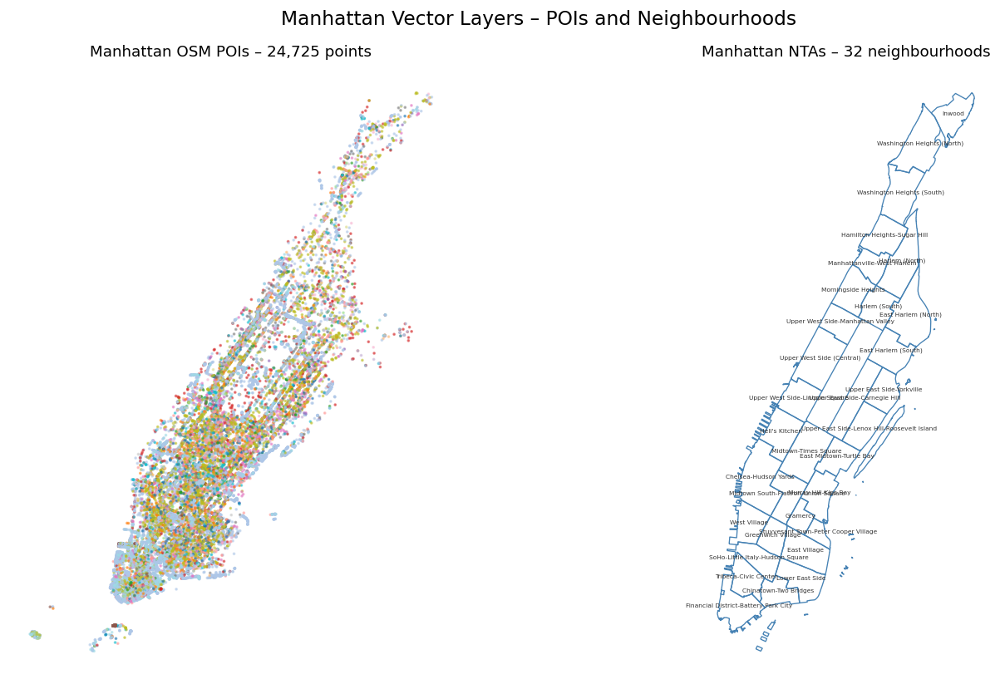

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

# --- LEFT PLOT: POIs ---
pois_man.plot(
    ax=axes[0],
    markersize=1.5,
    alpha=0.5,
    column='amenity',
    legend=False,
    cmap='tab20'
)

axes[0].set_title(
    f"Manhattan OSM POIs – {len(pois_man):,} points",
    fontsize=11
)
axes[0].set_aspect('equal')
axes[0].axis('off')

# --- RIGHT PLOT: NTAs ---
manhattan.boundary.plot(
    ax=axes[1],
    linewidth=0.8,
    color='steelblue'
)

# Label each neighbourhood
manhattan.apply(
    lambda row: axes[1].annotate(
        row['ntaname'],
        xy=row.geometry.centroid.coords[0],
        ha='center',
        fontsize=4.5,
        color='#333333'
    ),
    axis=1
)

axes[1].set_title(
    f"Manhattan NTAs – {len(manhattan)} neighbourhoods",
    fontsize=11
)
axes[1].axis('off')

plt.suptitle(
    "Manhattan Vector Layers – POIs and Neighbourhoods",
    fontsize=14
)

plt.tight_layout()
plt.show()


In [8]:
# Save POIs if file does not exist
if not POI_FILE.exists():
    pois_man.to_file(POI_FILE, driver='GeoJSON')

# Save NTAs if file does not exist
if not NTA_FILE.exists():
    manhattan.to_file(NTA_FILE, driver='GeoJSON')

# Print summary
print(f"POIs: {POI_FILE.name:30s} {len(pois_man):6,} points")
print(f"NTAs: {NTA_FILE.name:30s} {len(manhattan):6,} polygons")


POIs: osm_pois_manhattan.geojson     24,725 points
NTAs: manhattan_nta.geojson              32 polygons


#Shared helper:annotate NTA map with neighbouhood names

In [9]:
def annotate_ntas(ax, gdf, fontsize=4.5, color='#333333'):
    """
    Label each NTA polygon at its centroid.
    """
    for _, row in gdf.iterrows():
        # Get centroid coordinates
        cx, cy = row.geometry.centroid.coords[0]

        # Add annotation
        ax.annotate(
            row['ntaname'],
            xy=(cx, cy),
            ha='center',
            va='center',
            fontsize=fontsize,
            color=color,
        )


#load and inpect Manhattan NTA polygons

In [10]:
manhattan = gpd.read_file(NTA_FILE).to_crs(4326)

print(f"NTAs: {len(manhattan)}")
print(f"CRS: {manhattan.crs}")
print(f"Columns: {list(manhattan.columns)}")

print()
print("Area range (km²):")

NTAs: 32
CRS: EPSG:4326
Columns: ['shape_area', 'ntaname', 'cdtaname', 'shape_leng', 'boroname', 'ntatype', 'nta2020', 'borocode', 'countyfips', 'ntaabbrev', 'cdta2020', 'geometry']

Area range (km²):


In [11]:
# EPSG:2263 – NY State Plane (Long Island), US survey feet
# Used as canonical metric CRS for NYC spatial analysis

manhattan_proj = manhattan.to_crs(2263)

# Compute area in km²
FT2_PER_M2 = 10.7639
areas_ft2 = manhattan_proj.geometry.area
areas_m2 = areas_ft2 / FT2_PER_M2
areas_km2 = areas_m2 / 1e6

print(f"min: {areas_km2.min():.2f} km²")
print(f"max: {areas_km2.max():.2f} km²")
print(f"median: {areas_km2.median():.2f} km²")

print()
print(manhattan[['nta2020', 'ntaname']].head(10).to_string(index=False))


min: 0.52 km²
max: 2.76 km²
median: 1.47 km²

nta2020                              ntaname
 MN0101 Financial District-Battery Park City
 MN0102                 Tribeca-Civic Center
 MN0201      SoHo-Little Italy-Hudson Square
 MN0202                    Greenwich Village
 MN0203                         West Village
 MN0301                Chinatown-Two Bridges
 MN0302                      Lower East Side
 MN0303                         East Village
 MN0401                 Chelsea-Hudson Yards
 MN0402                       Hell's Kitchen


In [12]:
#Verify NTA composition composition matches what the guide assumes
#Cross-check the schema the rest of the guide assumes
#Fail loudly if anything has drifted


# Expected columns for Manhattan NTA file
expected_columns = {
    'shape_area', 'ntaname', 'cdtaname', 'boroname',
    'ntatype', 'nta2020', 'borocode', 'countyfips',
    'ntaabbrev', 'cdta2020', 'geometry'
}

# Validate number of NTAs
assert len(manhattan) == 32, f"Expected 32 NTAs, got {len(manhattan)}"

# Validate required columns
missing = expected_columns - set(manhattan.columns)
assert not missing, f"Missing columns: {missing}"

# Validate borough name
assert (manhattan['boroname'] == 'Manhattan').all(), (
    "Non-Manhattan NTAs present — wrong file."
)


In [13]:
#ntatype is the NYC DCP NTA-type code;0=standard residential NTA.#Non-residential types(parks,cemetries,airports) are filtered out # in the data-acquisition step,so this should be all -zero here.

# Inspect NTA type values
print("NTA type values:", manhattan["ntatype"].value_counts().to_dict())

# Check if all NTAs are residential type ("0")
all_residential = (manhattan["ntatype"] == "0").all()
print(f"All 32 NTAs are residential-type: {all_residential}")


NTA type values: {'0': 32}
All 32 NTAs are residential-type: True


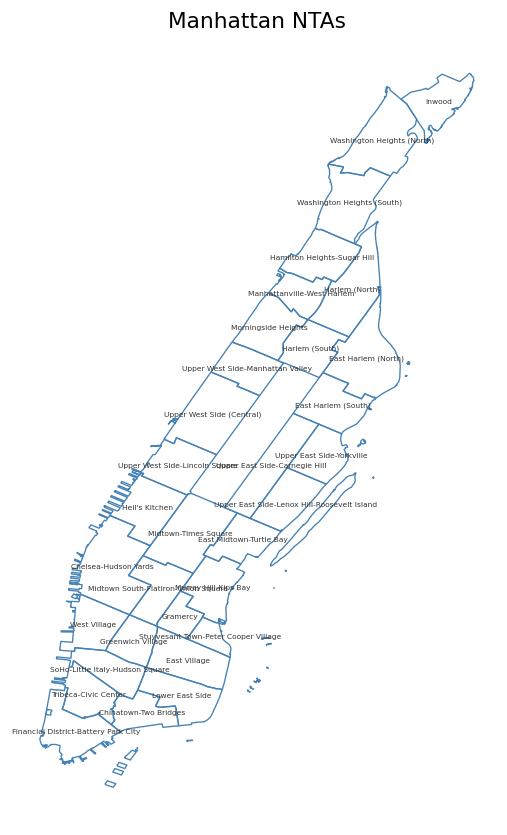

In [14]:
fig, ax = plt.subplots(figsize=(8.5, 8.5))

# Example: plot Manhattan boundary (adjust to your workflow)
manhattan.boundary.plot(ax=ax, linewidth=0.8, color='steelblue')

# Add NTA labels if needed
annotate_ntas(ax, manhattan)

ax.set_title("Manhattan NTAs")
ax.set_aspect("equal")
ax.axis("off")

plt.show()


In [15]:
#load OSM POI layer
pois = gpd.read_file(POI_FILE).to_crs(4326)

print(f'POIs:{len(pois):,}')
print(f'CRS:{pois.crs}')
print(f'Columns:{list(pois.columns)}')
print()

print('Top 10 amenity categories:')
print(pois['amenity'].value_counts().head(10).to_string())



POIs:24,725
CRS:EPSG:4326
Columns:['element', 'id', 'amenity', 'geometry']

Top 10 amenity categories:
amenity
bench              6159
bicycle_parking    3676
restaurant         3411
waste_basket       1743
fast_food          1529
cafe               1241
bicycle_rental      680
bar                 660
drinking_water      521
post_box            499


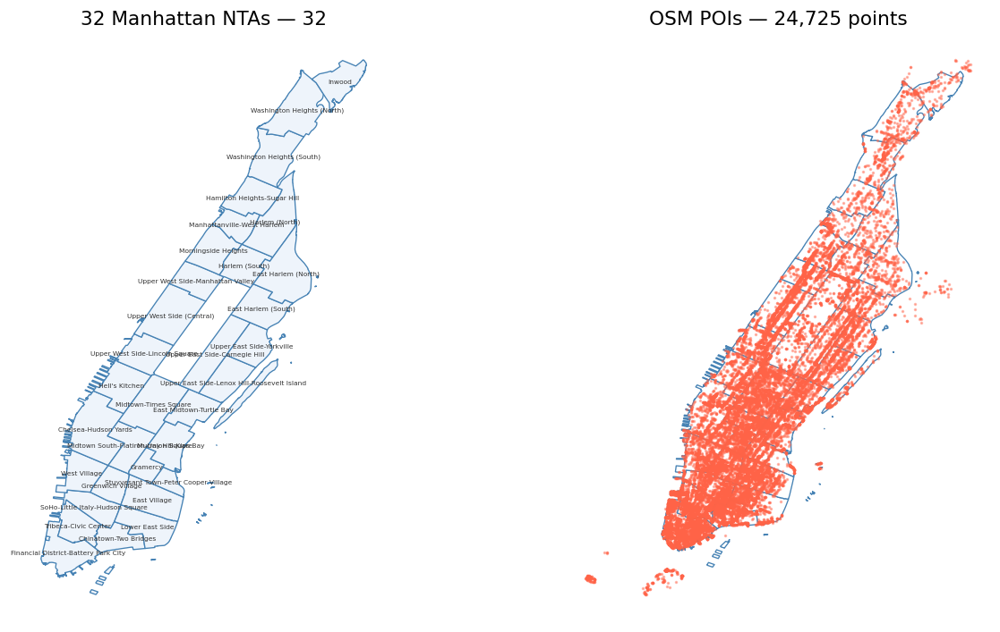

In [16]:
# Combined map: POI density over NTA boundaries

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# --- Left plot: Manhattan boundary ---
manhattan.boundary.plot(
    ax=axes[0],
    facecolor='#EEF4FB',
    linewidth=0.8,
    edgecolor='steelblue'
)
axes[0].set_title(f'32 Manhattan NTAs — {len(manhattan)}', fontsize=13)
annotate_ntas(axes[0], manhattan, fontsize=4.5)
axes[0].set_aspect('equal')
axes[0].axis('off')

# --- Right plot: POIs over NTA boundaries ---
manhattan.boundary.plot(
    ax=axes[1],
    linewidth=0.8,
    edgecolor='steelblue',
    facecolor='white',
    zorder=1
)

pois.plot(
    ax=axes[1],          # ← FIXED: use axes[1], not ax
    markersize=1.2,
    alpha=0.4,
    color='tomato',
    zorder=2
)

axes[1].set_title(f'OSM POIs — {len(pois):,} points', fontsize=13)
axes[1].set_aspect('equal')
axes[1].axis('off')

plt.tight_layout()
plt.show()



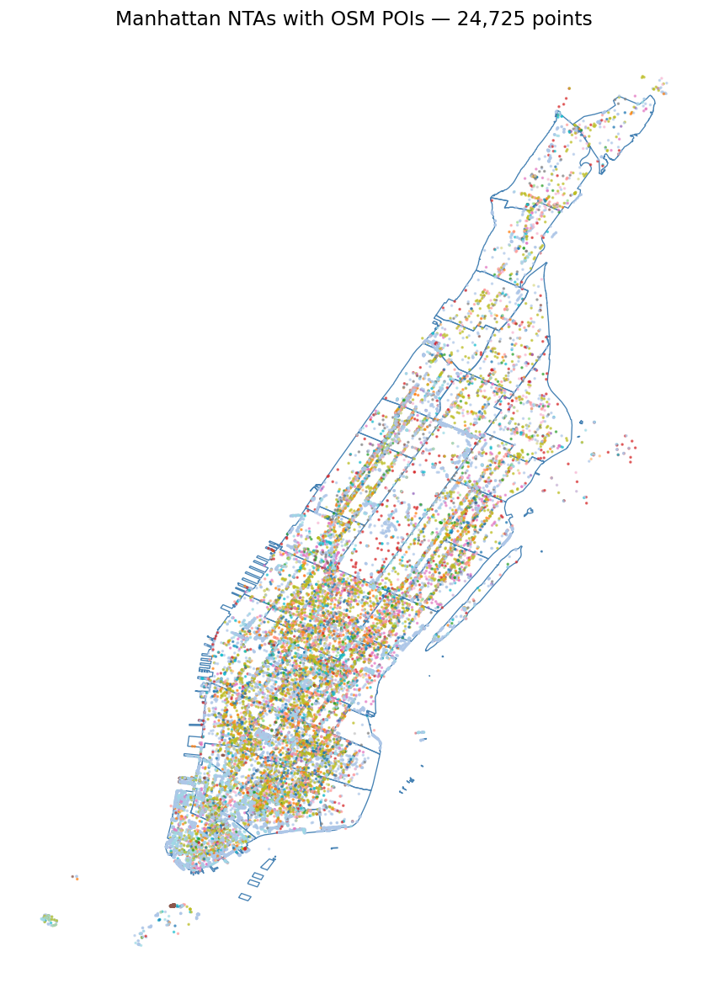

In [17]:
fig, ax = plt.subplots(1, 1, figsize=(10, 10))

# --- Layer 1: Manhattan neighbourhood boundaries ---
manhattan.boundary.plot(
    ax=ax,
    linewidth=0.8,
    color='steelblue',
    zorder=1
)

# --- Layer 2: POIs ---
pois.plot(
    ax=ax,
    markersize=1.2,
    alpha=0.6,
    column='amenity',   # color by amenity category
    cmap='tab20',
    legend=False,
    zorder=2
)

ax.set_title(f'Manhattan NTAs with OSM POIs — {len(pois):,} points', fontsize=14)
ax.set_aspect('equal')
ax.axis('off')

plt.tight_layout()
plt.show()


In [18]:
# Groq LLM wrapper
# The API key is read from config.txt (one line: your Groq key).
# This keeps the key out of the notebook itself.
# Never paste a real key into a cell.

from pathlib import Path
from groq import Groq

def load_groq_key(path='config.txt'):
    """
    Read the Groq API key from config.txt.
    Fail with a clear message if the file is missing or contains a placeholder.
    """
    if not Path(path).exists():
        raise FileNotFoundError(
            f"{path} not found. Create it with one line containing your Groq key.\n"
            "Get a free key at https://console.groq.com/keys"
        )

    key = Path(path).read_text().strip()

    if not key or key.startswith("gsk_..."):
        raise ValueError(
            f"No real key in {path}. Open it and replace the placeholder with your "
            "actual Groq key from https://console.groq.com/keys"
        )

    return key


# Load key and initialize client
GROQ_API_KEY = load_groq_key()
MODEL_NAME="openai/gpt-oss-120b"
client = Groq(api_key=GROQ_API_KEY)


def call_llm(messages: list, system: str) -> str:
    """
    Send a conversation to Groq and return the reply as a string.
    """
    full_messages = [{'role': 'system', 'content': system}] + messages

    response = client.chat.completions.create(
        model=MODEL_NAME,
        messages=full_messages,
        temperature=0,        # greedy decoding
        max_tokens=2048       # enough for long NTA ranking outputs
    )

    return response.choices[0].message.content.strip()


In [19]:
# LLM smoke test
reply = call_llm(
    messages=[{'role': 'user', 'content': 'Name the five boroughs of New York City.'}],
    system='You are a helpful assistant. Be concise.'
)

print(reply)

The five boroughs of New York City are:

1. Manhattan  
2. Brooklyn  
3. Queens  
4. The Bronx  
5. Staten Island


In [20]:
#Build STRtree spatial index in EPSG:2263
#2263 is NY State Plane (Long Island);its unit is the US surveu foot.
#Building the tree in a metric CRS lets every radius buffer be a true circle on the ground (a buffer in EPSG:4326 is an ellipse).
#We keep the WGS-84 data frames('pois','manhattan') for display and precompute 2263 versions for spatial operations.

FT_PER_M=3397/1200 #Exact US survey foot to meter conversion

In [21]:
import geopandas as gpd

POI_FILE = r"C:\Users\User\Desktop\GEOAI\data\osm_pois_manhattan.geojson"
NTA_FILE = r"C:\Users\User\Desktop\GEOAI\data\manhattan_nta.geojson"

pois = gpd.read_file(POI_FILE).to_crs(4326)
manhattan = gpd.read_file(NTA_FILE).to_crs(4326)

print(f"Loaded {len(pois):,} POIs")
print(f"Loaded {len(manhattan):,} NTA polygons")


Loaded 24,725 POIs
Loaded 32 NTA polygons


In [22]:
valid_mask = pois.geometry.notna() & ~pois.geometry.is_empty
pois = pois[valid_mask].reset_index(drop=True)

print(f"POIs after geometry filter: {len(pois):,} ({(~valid_mask).sum()} removed)")


POIs after geometry filter: 24,725 (0 removed)


In [23]:
pois_2263 = pois.to_crs(2263)


In [24]:
from shapely.strtree import STRtree
poi_tree = STRtree(pois_2263.geometry)

print(f"STRtree built over {len(pois):,} POIs")


STRtree built over 24,725 POIs


In [25]:
def pois_in_polygon(polygon_2263):
    idx = poi_tree.query(polygon_2263, predicate='intersects')
    return pois.iloc[idx]


In [26]:
# ln 15 Radius query primitive and sanity check
import geopandas as gpd
from shapely.geometry import Point

FT_PER_M = 3.28084   # meters → US survey feet

# Radius query primitive
def points_near_point(layer, tree, lat: float, lon: float, radius_m: float):
    """
    Return rows of 'layer' (in EPSG:4326) within radius_m of (lat, lon).
    'tree' must be an STRtree built over the same layer reprojected to EPSG:2263.
    """
    # Convert meters → feet (NY State Plane uses US survey feet)
    radius_ft = radius_m * FT_PER_M

    # Create point in EPSG:4326 then project to EPSG:2263
    pt_2263 = gpd.GeoSeries([Point(lon, lat)], crs=4326).to_crs(2263).iloc[0]

    # Create a circular buffer in real-world units
    circle = pt_2263.buffer(radius_ft)

    # Query STRtree
    idx = tree.query(circle, predicate='intersects')

    return layer.iloc[idx]


def pois_near_point(lat: float, lon: float, radius_m: float):
    """Convenience wrapper for querying the POI layer."""
    return points_near_point(pois, poi_tree, lat, lon, radius_m)


# Test query: POIs within 500m of Empire State Building
print(
    f"Test — POIs near Empire State Building (500m): "
    f"{len(pois_near_point(40.7484, -73.9857, 500)):,}"
)



Test — POIs near Empire State Building (500m): 568


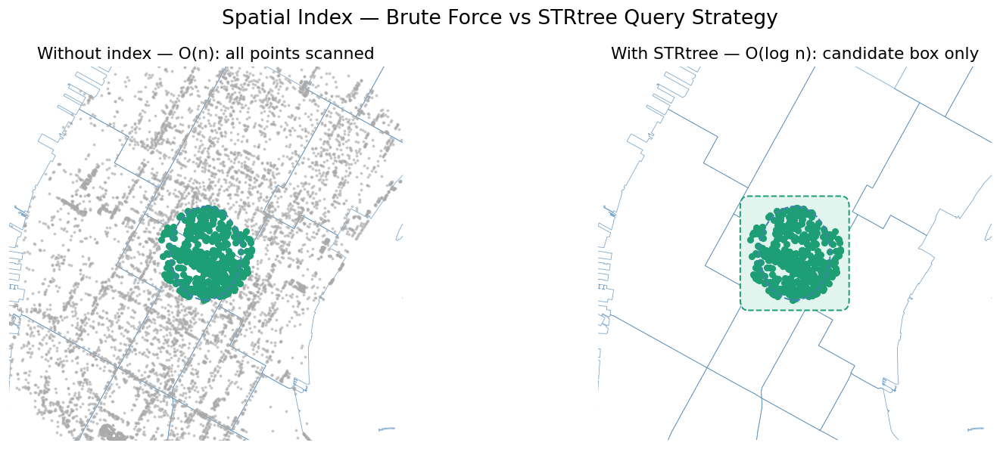

In [27]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from shapely.geometry import Point
import geopandas as gpd

# Query point: Empire State Building
query_lat, query_lon = 40.7484, -73.9857
RADIUS_M = 500
FT_PER_M = 3.28084

# Build query buffer in EPSG:2263
pt_2263 = gpd.GeoSeries([Point(query_lon, query_lat)], crs=4326).to_crs(2263)
buffer_2263 = pt_2263.buffer(RADIUS_M * FT_PER_M)

# STRtree candidate envelope (bounding box)
# IMPORTANT: extract the shapely geometry with .iloc[0]
envelope_4326 = gpd.GeoSeries([buffer_2263.iloc[0].envelope], crs=2263).to_crs(4326)
minx, miny, maxx, maxy = envelope_4326.total_bounds

# Brute-force vs STRtree hits
all_near = pois_near_point(query_lat, query_lon, 2500)
hits = pois_near_point(query_lat, query_lon, RADIUS_M)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Cosmetic dashed circle (lat-degree approximation)
radius_deg = RADIUS_M / 111_000

for ax in axes:
    # Manhattan boundary
    manhattan.boundary.plot(ax=ax, linewidth=0.5, color="steelblue", alpha=0.7)

    # Map extent
    ax.set_xlim(query_lon - 0.025, query_lon + 0.025)
    ax.set_ylim(query_lat - 0.018, query_lat + 0.018)
    ax.axis("off")

    # Dashed circle
    circ = mpatches.Circle(
        (query_lon, query_lat),
        radius_deg,
        fill=False,
        edgecolor="steelblue",
        linewidth=1.2,
        linestyle="--",
        zorder=4,
        transform=ax.transData,
    )
    ax.add_patch(circ)

# LEFT PANEL — brute force O(n)
axes[0].scatter(
    all_near.geometry.x,
    all_near.geometry.y,
    s=2,
    color="#aaaaaa",
    alpha=0.5,
    zorder=2,
)
axes[0].scatter(
    hits.geometry.x,
    hits.geometry.y,
    s=20,
    color="#1D9E75",
    zorder=3,
)
axes[0].set_title("Without index — O(n): all points scanned", fontsize=13)

# RIGHT PANEL — STRtree O(log n)
bbox = mpatches.FancyBboxPatch(
    (minx, miny),
    (maxx - minx),
    (maxy - miny),
    boxstyle="round,pad=0.001",
    facecolor="#E1F5EE",
    edgecolor="#1D9E75",
    linewidth=1.2,
    linestyle="--",
    zorder=2,
)
axes[1].add_patch(bbox)

axes[1].scatter(
    hits.geometry.x,
    hits.geometry.y,
    s=20,
    color="#1D9E75",
    zorder=3,
)
axes[1].set_title("With STRtree — O(log n): candidate box only", fontsize=13)

plt.suptitle("Spatial Index — Brute Force vs STRtree Query Strategy", fontsize=16)
plt.tight_layout()
plt.show()


In [28]:
#ln 17

from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter

_geolocator = Nominatim(user_agent="geoai_agent_ch14")
_geocode_rl = RateLimiter(_geolocator.geocode, min_delay_seconds=1)

def find_nta(name: str):
    """
    Return NTA rows matching name — exact match first, then partial match.
    """
    # Exact match (case-insensitive)
    exact = manhattan[manhattan["ntaname"].str.lower() == name.lower()]
    if len(exact):
        return exact

    # Partial match (substring search)
    partial = manhattan[
        manhattan["ntaname"].str.lower().str.contains(name.lower())
    ]
    return partial



In [29]:
find_nta("Harlem")
find_nta("east")
find_nta("Upper West Side")
find_nta("wash")   # Washington Heights, etc.


,shape_area,ntaname,cdtaname,shape_leng,boroname,ntatype,nta2020,borocode,countyfips,ntaabbrev,cdta2020,geometry
29,21027667.0742,Washington Heights (South),MN12 Washington Heights-Inwood (CD 12 Equivalent),22198.2296543,Manhattan,0,MN1201,1,061,WshHts_S,MN12,"MULTIPOLYGON (((-73.93139 40.84743, -73.93185 ..."
30,24771531.3427,Washington Heights (North),MN12 Washington Heights-Inwood (CD 12 Equivalent),26727.3690107,Manhattan,0,MN1202,1,061,WshHts_N,MN12,"MULTIPOLYGON (((-73.92873 40.86674, -73.92806 ..."


In [30]:
#ln18 # ── Tool 1: geocode — address string to lat/lon

def geocode(address: str) -> str:
    """
    Translate an address to lat/lon via Nominatim.
    """
    try:
        loc = _geocode_rl(address + ", Manhattan, New York City")
    except Exception as e:
        return f"Geocoding failed: {e}"

    if loc is None:
        return f"Could not geocode: {address}"

    return (
        f"{loc.address} | "
        f"lat={loc.latitude:.5f} lon={loc.longitude:.5f}"
    )


In [31]:
#ln19 # ── Category discovery (data-driven) ─────────────────────────── 
# Rather than hand-maintain a list of categories, we read them straight 
# from the data: every distinct `amenity` value present in the POI layer # is a valid category. This keeps the agent honest — it can only be asked
# for things that actually exist in the data — and means a richer POI # download automatically widens what the agent can answer, with no code 
# change here.
#
# `resolve_category` does light normalisation so natural-language inputs
# map onto OSM tag spelling: lowercasing, spaces->underscores, and a small 
# set of common synonyms (e.g. 'pub' -> 'bar', 'coffee' -> 'cafe').


AMENITY_COLUMN = "amenity"

# Distinct amenity values actually present in the POI layer.
AVAILABLE_CATEGORIES = set(
    pois[AMENITY_COLUMN].dropna().str.lower().unique()
)



CATEGORY_ALIASES = {
    "pub": "bar",
    "pubs": "bar",
    "bars": "bar",

    "coffee": "cafe",
    "coffee_shop": "cafe",
    "cafes": "cafe",

    "restaurant": "restaurant",
    "restaurants": "restaurant",
    "diner": "restaurant",

    "fast food": "fast_food",
    "fastfood": "fast_food",

    "pharmacies": "pharmacy",
    "chemist": "pharmacy",
    "drugstore": "pharmacy",

    "schools": "school",
    "banks": "bank",

    "theater": "theatre",
    "theatres": "theatre",
}


def resolve_category(category: str):
    """
    Normalise a user-facing category to an OSM amenity value present in the data.
    Returns the canonical value, or raises KeyError with suggested alternatives.
    """
    key = category.strip().lower().replace(" ", "_")
    key = CATEGORY_ALIASES.get(key, key)

    if key in AVAILABLE_CATEGORIES:
        return key

    # Fallback: substring match (e.g. "food" → "fast_food")
    near = sorted(
        v for v in AVAILABLE_CATEGORIES
        if key in v or v in key
    )

    raise KeyError(
        f"'{category}' is not an amenity in the data."
        + (f" Did you mean: {near}?" if near else "")
    )


print(f"{len(AVAILABLE_CATEGORIES)} amenity categories available in the POI layer.")
print("Most common:", pois[AMENITY_COLUMN].value_counts().head(10).index.tolist())



132 amenity categories available in the POI layer.
Most common: ['bench', 'bicycle_parking', 'restaurant', 'waste_basket', 'fast_food', 'cafe', 'bicycle_rental', 'bar', 'drinking_water', 'post_box']


In [32]:
resolve_category("coffee")
resolve_category("pubs")
resolve_category("fast food")
resolve_category("drugstore")
resolve_category("wash")   # should raise KeyError with suggestions


KeyError: "'wash' is not an amenity in the data. Did you mean: ['car_wash']?"

In [ ]:
resolve_category("car wash")     # alias → car_wash
resolve_category("wash")         # KeyError with suggestion
resolve_category("car_wash")     # exact match
resolve_category("food")         # likely → fast_food
resolve_category("coffee")       # → cafe
resolve_category("pubs")         # → bar


In [ ]:
def pois_in_nta(nta_name: str, category: str):
    nta = find_nta(nta_name)
    cat = resolve_category(category)
    return pois[pois["amenity"].str.lower() == cat].clip(nta.geometry)


In [ ]:
#In [20]: # ── Tool 2: find_pois_near — radius query with category filter

def find_pois_near(
    lat: float,
    lon: float,
    radius_m: float,
    category: str = None,
) -> str:
    """
    POIs within radius_m of (lat, lon), optionally filtered by category.
    Categories are resolved with resolve_category (data-driven) and matched
    against the amenity column.
    """

    # No category: query the main POI layer with no filter.
    if category is None:
        nearby = pois_near_point(lat, lon, radius_m)
        column_used = "amenity"

    else:
        try:
            amenity = resolve_category(category)
        except KeyError as e:
            return str(e)

        nearby = pois_near_point(lat, lon, radius_m)
        nearby = nearby[nearby[AMENITY_COLUMN].str.lower() == amenity]
        column_used = AMENITY_COLUMN

    # No results
    if len(nearby) == 0:
        suffix = f" for category '{category}'" if category else ""
        return f"No POIs found within {radius_m:.0f}m{suffix}"

    # Summary of top categories
    summary = nearby[column_used].value_counts().head(10)

    header_line = (
        f"{len(nearby)} POIs within {radius_m:.0f}m"
        + (f" (category: {category})" if category else "")
    )

    return header_line + ":\n" + summary.to_string()



In [ ]:
#test the above
find_pois_near(40.7484, -73.9857, 300)                 # All POIs near ESB
find_pois_near(40.7484, -73.9857, 300, "coffee")       # Cafes
find_pois_near(40.7484, -73.9857, 300, "pubs")         # Bars
find_pois_near(40.7484, -73.9857, 300, "wash")         # Should give KeyError suggestion


In [ ]:
#In [21]: # ── Tool 3: count_pois — per-NTA count or full 32-NTA ranking ─────────  

def _count_in_polygon(poly_2263, amenity):
    # Query spatial index for intersecting POIs
    idx = poi_tree.query(poly_2263, predicate='intersects')

    # Subset POIs using the index
    subset = pois.iloc[idx]

    # Count matching amenity
    return int((subset[AMENITY_COLUMN].str.lower() == amenity).sum())

def count_pois(category: str, neighbourhood: str = None) -> str:
    """
    Count category POIs in one NTA, or rank the NTAs with more than 10 matches
    if neighbourhood is None.
    """

    # Resolve category → canonical amenity
    try:
        amenity = resolve_category(category)
    except KeyError as e:
        return str(e)

    # If neighbourhood is None → rank all NTAs
    is_all = (
        neighbourhood is None
        or neighbourhood.lower() in ('all', 'every', '')
    )

    if is_all:
        results = []

        # Iterate through Manhattan polygons in both CRS
        for (_, row), (_, row_2263) in zip(
            manhattan.iterrows(), manhattan_2263.iterrows()
        ):
            c = _count_in_polygon(row_2263.geometry, amenity)
            results.append((row['ntaname'], c))

        # Sort by count
        results.sort(key=lambda x: x[1])

        # Only show NTAs with >10 POIs
        lines = '\n'.join(
            f' {n:<35} {c}' for n, c in results if c > 10
        )

        return f"Ranking of Manhattan NTAs by '{category}' count:\n{lines}"

    # Otherwise → count POIs in one neighbourhood
    nta = find_nta(neighbourhood)

    if len(nta) == 0:
        available = ', '.join(manhattan['ntaname'].tolist())
        return (
            f"Neighbourhood '{neighbourhood}' not found. "
            f"Available: {available}"
        )

    name = nta['ntaname'].iloc[0]

    # Reproject matched polygon to EPSG:2263
    poly_2263 = manhattan_2263[
        manhattan_2263['ntaname'] == name
    ].geometry.iloc[0]

    c = _count_in_polygon(poly_2263, amenity)

    return f"{name}: {c} POIs in category '{category}'"



In [ ]:
count_pois("coffee")
count_pois("pubs")
count_pois("fast food")
count_pois("drugstore")
count_pois("wash")          # Should give KeyError with suggestion
count_pois("coffee", "Harlem")
count_pois("bar", "Upper West Side")
count_pois("cafe", "wash")  # Should give neighbourhood not found


In [ ]:
# — Tool 4: summarise_neighbourhood — POI composition of one NTA
def summarise_neighbourhood(neighbourhood: str) -> str:
    """Return top POI categories and counts for the named NTA."""
    nta = find_nta(neighbourhood)
    if len(nta) == 0:
        available = ','.join(manhattan['ntaname'].tolist())
        return (
            f"Neighbourhood '{neighbourhood}' not found. "
            f"Available: {available}"
        )

    name = nta['ntaname'].iloc[0]
    poly_2263 = manhattan_2263[
        manhattan_2263['ntaname'] == name
    ].geometry.iloc[0]

    subset = pois_in_polygon(poly_2263)
    top = subset['amenity'].value_counts().head(10)

    return (
        f"{name} — {len(subset)} total POIs\n"
        f"Top categories:\n{top.to_string()}"
    )


In [ ]:
# — Tool 5: compare_neighbourhoods — side-by-side summary
def compare_neighbourhoods(name1: str, name2: str) -> str:
    """Side-by-side POI summary for two NTAs."""
    r1 = summarise_neighbourhood(name1)
    r2 = summarise_neighbourhood(name2)
    return f"=== {name1} ===\n\n{r1}\n\n=== {name2} ===\n\n{r2}"


In [ ]:
# — Quick test of all five tools ————————————————
print('Testing geocode():')
print(geocode('Empire State Building'))
print('\n' + '—' * 60 + '\n')

print('Testing find_pois_near() — cafes within 300 m:')
print(find_pois_near(40.7484, -73.9857, 300, category='cafe'))
print('\n' + '—' * 60 + '\n')

print('Testing count_pois() — bars in one neighbourhood:')
print(count_pois('bar', 'East Village'))
print('\n' + '—' * 60 + '\n')

print('Testing count_pois() — city-wide ranking (neighbourhood=None):')
print(count_pois('bar'))
print('\n' + '—' * 60 + '\n')

print('Testing summarise_neighbourhood():')
print(summarise_neighbourhood('Harlem'))
print('\n' + '—' * 60 + '\n')

print('Testing compare_neighbourhoods():')
print(compare_neighbourhoods("Hell's Kitchen", "East Village"))


In [ ]:
#ln 25

SYSTEM_PROMPT = f"""
You are a geospatial assistant for Manhattan, New York City.
You have access to five spatial tools.
Always respond with ONLY a JSON object — no prose, no markdown.

Available tools:

1. geocode
Input: {{"tool": "geocode", "params": {{"address": "<string>"}}}}
Output: street address + lat/lon

2. find_pois_near
Input: {{"tool": "find_pois_near", "params": {{"lat": <float>, "lon": <float>, "radius_m": <float>, "category": "<string>"}}}}
Output: count and top-category summary for the radius

3. count_pois
Input: {{"tool": "count_pois", "params": {{"category": "<string>", "neighbourhood": "<string or null>"}}}}
Output: count for one NTA, or ranking of NTAs with more than 10 matches

4. summarise_neighbourhood
Input: {{"tool": "summarise_neighbourhood", "params": {{"neighbourhood": "<string>"}}}}
Output: top POI categories and counts for that neighbourhood

5. compare_neighbourhoods
Input: {{"tool": "compare_neighbourhoods", "params": {{"name1": "<string>", "name2": "<string>"}}}}
Output: side-by-side POI summaries

When you have the information to answer, respond with:
{{"tool": "answer", "params": {{"text": "<final natural language answer>"}}}}

Rules:
- Use one tool per response
- Categories are matched EXACTLY. Available categories: {sorted(AVAILABLE_CATEGORIES)}
- Neighbourhood names must match Manhattan NTAs (partial matches are accepted)
- For "which neighbourhood" questions, call count_pois with neighbourhood=None
- Call geocode first for street addresses or specific landmarks (e.g., "Empire State Building")
"""


In [ ]:
#ln26

# ── Tool registry — maps JSON tool names to Python callables
TOOL_MAP = {
    'geocode': geocode,
    'find_pois_near': find_pois_near,
    'count_pois': count_pois,
    'summarise_neighbourhood': summarise_neighbourhood,
    'compare_neighbourhoods': compare_neighbourhoods,
}



In [ ]:
#ln 27

# —— Agent loop: query → tool dispatch → answer
def run_agent(query: str, max_steps: int = 10, verbose: bool = True) -> str:
    """Run the ReAct-style tool loop until the LLM emits a final answer."""
    messages = [{'role': 'user', 'content': query}]

    for step in range(max_steps):
        raw = call_llm(messages, system=SYSTEM_PROMPT)
        clean = raw.strip().strip('`').strip()

        if clean.startswith('json'):
            clean = clean[4:]

        try:
            parsed = json.loads(clean)
            tool_name = parsed['tool']
            params = parsed.get('params', {})

        except (json.JSONDecodeError, KeyError):
            # LLM returned prose instead of JSON — treat as final answer
            return raw

        if tool_name == 'answer':
            return params.get('text', raw)

        if tool_name not in TOOL_MAP:
            return f'Unknown tool: {tool_name}'

        # Execute tool
        result = TOOL_MAP[tool_name](**params)
        if not result:
            result = f"Tool {tool_name} returned no results."

        if verbose:
            label = ', '.join(f"{k}={v!r}" for k, v in params.items())
            print(f"[{step + 1}] {tool_name}({label})")

        if len(result) > 20:
            print(f" → {result}\n")

        # Accumulate full conversation — LLM reads all previous decisions
        messages.append({'role': 'assistant', 'content': raw})
        messages.append({'role': 'user', 'content': f"Tool result:\n{result}"})

    return "Max steps reached without a final answer."







In [ ]:
print("run_agent" in globals())

In [ ]:
# Agent loop: query → tool dispatch → answer
def run_agent(query: str, max_steps: int = 10, verbose: bool = True) -> str:
    """Run the ReAct-style tool loop until the LLM emits a final answer."""
    messages = [{'role': 'user', 'content': query}]

    for step in range(max_steps):
        raw = call_llm(messages, system=SYSTEM_PROMPT)
        clean = raw.strip().strip('`').strip()

        if clean.startswith('json'):
            clean = clean[4:]

        try:
            parsed = json.loads(clean)
            tool_name = parsed['tool']
            params = parsed.get('params', {})

        except (json.JSONDecodeError, KeyError):
            return raw

        if tool_name == 'answer':
            return params.get('text', raw)

        if tool_name not in TOOL_MAP:
            return f'Unknown tool: {tool_name}'

        result = TOOL_MAP**params

        if not result:
            result = f"Tool {tool_name} returned no results."

        if verbose:
            label = ', '.join(f"{k}={v!r}" for k, v in params.items())
            print(f"[{step + 1}] {tool_name}({label})")

        if len(result) > 20:
            print(f" → {result}\n")

        messages.append({'role': 'assistant', 'content': raw})
        messages.append({'role': 'user', 'content': f"Tool result:\n{result}"})

    return "Max steps reached without a final answer."

In [ ]:
print(run_agent)

In [ ]:
print("run_agent:", "run_agent" in globals())
print("call_llm:", "call_llm" in globals())
print("SYSTEM_PROMPT:", "SYSTEM_PROMPT" in globals())
print("TOOL_MAP:", "TOOL_MAP" in globals())
print("json:", "json" in globals())

In [ ]:
import json

In [ ]:
print("json" in globals())


In [ ]:
print("call_llm" in globals())
print("SYSTEM_PROMPT" in globals())
print("TOOL_MAP" in globals())

In [ ]:
print("call_llm" in globals())
print("SYSTEM_PROMPT" in globals())
print("TOOL_MAP" in globals())

In [ ]:
print(type(call_llm))
print(call_llm)

In [ ]:
print(call_llm.__name__)
print(call_llm.__module__)
print(call_llm.__doc__)

In [ ]:
import inspect

print(inspect.signature(call_llm))

In [ ]:
import inspect

print(inspect.getfile(call_llm))


In [ ]:
import inspect

print(inspect.getsource(call_llm))

In [ ]:
import inspect
print(inspect.signature(call_llm))
print(inspect.getfile(call_llm))

In [ ]:
import re

for name, obj in globals().items():
    try:
        text = inspect.getsource(obj)
        if "call_llm(" in text:
            print(name)
    except:
        pass

In [ ]:
call_llm(

In [ ]:
import inspect

for name, obj in list(globals().items()):
    try:
        text = inspect.getsource(obj)
        if "call_llm(" in text:
            print(name)
    except Exception:
        pass

In [ ]:
g = dict(globals())

for name, obj in g.items():
    try:
        text = inspect.getsource(obj)
        if "call_llm(" in text:
            print(name)
    except Exception:
        pass

In [ ]:
call_llm(
    messages=[
        {"role": "user", "content": "Hello"}
    ],
    system="You are a helpful assistant."
)

In [ ]:
print(call_llm.__code__.co_names)

In [ ]:
print("MODEL_NAME =", call_llm.__globals__.get("MODEL_NAME"))

print("client =", call_llm.__globals__.get("client"))
print("client type =", type(call_llm.__globals__.get("client")))

In [ ]:
sorted(call_llm.__globals__.keys())

In [ ]:
for k in sorted(call_llm.__globals__):
    if any(x in k.lower() for x in [
        "model", "client", "prompt", "tool",
        "groq", "api", "system"
    ]):
        print(k)

In [ ]:
full_messages = [{'role': 'system', 'content': system}] + messages

In [ ]:
import inspect

for name, obj in list(globals().items()):
    try:
        src = inspect.getsource(obj)
        if "call_llm(" in src and name != "call_llm":
            print(f"\n--- {name} ---")
            print(src[:500])
    except Exception:
        pass

In [ ]:
system = "You are a helpful assistant."

messages = [
    {"role": "user", "content": "Hello"}
]

full_messages = [{"role": "system", "content": system}] + messages

print(full_messages)

In [ ]:
for k, v in globals().items():
    if isinstance(v, str) and len(v) > 50:
        print(f"\n{k}:")
        print(v[:300])

In [ ]:
for k, v in list(globals().items()):
    if isinstance(v, str) and len(v) > 50:
        print(f"\n{k}:")
        print(v[:300])

In [ ]:
print(call_llm.__code__.co_names)

In [ ]:
print(call_llm.__globals__.get("MODEL_NAME"))

In [ ]:
[k for k in call_llm.__globals__.keys()
 if any(x in k.lower() for x in
        ["model", "client", "groq", "api", "system"])]

In [ ]:
for k, v in list(call_llm.__globals__.items()):
    if isinstance(v, str) and len(v) > 100:
        print("\nNAME:", k)
        print(v[:500])

In [ ]:
print(call_llm.__code__.co_names)

In [ ]:
print("MODEL_NAME =", call_llm.__globals__.get("MODEL_NAME"))
print("client =", call_llm.__globals__.get("client"))
print("co_names =", call_llm.__code__.co_names)

In [ ]:
client_obj = call_llm.__globals__["client"]

print(type(client_obj))
print(dir(client_obj))

In [ ]:
MODEL_NAME

In [ ]:
call_llm.__globals__["MODEL_NAME"]

In [ ]:
for k in sorted(list(globals().keys())):
    print(k)


In [ ]:
print("SYSTEM:")
print(system)

In [ ]:
print("MESSAGES:")
print(messages)

In [ ]:
print("FULL_MESSAGES:")
print(full_messages)

In [ ]:
from pprint import pprint

pprint(full_messages)

In [ ]:
print(type(system))
print(type(messages))
print(type(full_messages))
print(type(reply))

In [ ]:
for name in sorted(globals()):
    if name.startswith("_i"):
        cell = globals()[name]
        if isinstance(cell, str) and "system" in cell:
            print(f"\n{name}")
            print("-" * 50)
            print(cell[:1000])

In [ ]:
for name in sorted(globals()):
    if name.startswith("_i"):
        cell = globals()[name]
        if isinstance(cell, str) and "call_llm(" in cell:
            print(f"\n{name}")
            print("-" * 50)
            print(cell[:1000])

In [ ]:
call_llm(messages, system)

In [ ]:
repr(system)

In [ ]:
#line 28

# — Agent loop smoke test
test_answer = run_agent('How many bars are in the East Village?')
print(f'Answer: {test_answer}')






In [ ]:
print("run_agent" in globals())

In [ ]:
for name, cell in list(globals().items()):
    if name.startswith("_i") and isinstance(cell, str):
        if "def run_agent" in cell:
            print(f"\n{name}")
            print(cell)

In [ ]:
for name, cell in list(globals().items()):
    if name.startswith("_i") and isinstance(cell, str):
        if "run_agent" in cell:
            print(f"\n{name}")
            print(cell[:1000])

In [ ]:
import inspect

for k, v in list(globals().items()):
    if inspect.isfunction(v):
        print(k)

In [ ]:
for name, cell in list(globals().items()):
    if name.startswith("_i") and isinstance(cell, str):
        if "def run_agent" in cell:
            print(f"\nFound in {name}")
            print(cell)

In [ ]:
for name, cell in list(globals().items()):
    if name.startswith("_i") and isinstance(cell, str):
        if "run_agent" in cell:
            print(f"\n{name}")
            print("-" * 60)
            print(cell[:1000])

In [ ]:
print("run_agent" in globals())

In [ ]:
import inspect

for name, obj in list(globals().items()):
    if inspect.isfunction(obj):
        print(name)

In [ ]:
for i, cell in enumerate(_ih):
    if "run_agent" in cell:
        print(f"\nCell {i}")
        print("-" * 60)
        print(cell[:2000])

In [ ]:
def run_agent(question):
    system = "You are a helpful GIS and GeoAI assistant."

    messages = [
        {"role": "user", "content": question}
    ]

    return call_llm(messages, system)

In [ ]:
test_answer = run_agent(
    "How many bars are in the East Village?"
)

print(test_answer)

In [ ]:
#line 28

# — Agent loop smoke test
test_answer = run_agent('How many bars are in the East Village?')
print(f'Answer: {test_answer}')

In [ ]:
def run_agent(question):
    """
    Simple agent that sends the user's question to the LLM.
    """

    system = """
    You are a GeoAI assistant for New York City spatial analysis.

    Answer geographic questions about:
    - NTAs (Neighborhood Tabulation Areas)
    - Points of Interest (POIs)
    - Distances and proximity
    - Counts of amenities

    Be concise and accurate.
    """

    messages = [
        {
            "role": "user",
            "content": question
        }
    ]

    return call_llm(messages, system)

In [ ]:
# --- Example 1: proximity lookup

q1 = "How many cafes are within 500 metres of the Empire State Building?"

print(f"Query: {q1}\n")

answer1 = run_agent(q1)

print(f"\nAnswer: {answer1}")

In [ ]:
print(POI_FILE)
print(len(pois))

In [ ]:
print(AVAILABLE_CATEGORIES)

In [ ]:
print(resolve_category("cafe"))

In [ ]:
print(geocode("Empire State Building"))

In [ ]:
pois_man
pois
valid_mask
missing

In [ ]:
print(len(pois))
print(pois.columns.tolist())

In [ ]:
print(resolve_category("cafe"))

In [ ]:
print(geocode("Empire State Building"))

In [ ]:
print(len(pois))
print(pois.columns.tolist())
print(resolve_category("cafe"))

In [ ]:
import inspect

print(inspect.getsource(pois_near_point))

In [ ]:
import inspect

print(inspect.signature(pois_near_point))

In [ ]:
import inspect

print(inspect.getsource(pois_near_point))

In [ ]:
print(resolve_category("cafe"))

In [ ]:
import inspect

print(inspect.getsource(points_near_point))

In [ ]:
print(pois.columns.tolist())

In [ ]:
nearby = pois_near_point(
    40.74844,
    -73.98566,
    500
)

print(len(nearby))
print(nearby.head())

In [ ]:
print(nearby["amenity"].value_counts())


In [ ]:
print(resolve_category("cafe"))

In [ ]:
print(resolve_category("cafe"))

In [ ]:
print(CATEGORY_ALIASES)

In [ ]:
nearby = pois_near_point(40.74844, -73.98566, 500)

print(nearby["amenity"].value_counts())

In [ ]:
nearby["amenity"].value_counts().head(20)

In [ ]:
pois = pois[valid_mask]

In [ ]:
lat, lon = 40.74844, -73.98566

cafes = pois_near_point(
    lat,
    lon,
    radius_m=500,
    category="cafe"
)

print("Count =", len(cafes))

In [ ]:
cafes.head()

In [ ]:
nearby = pois_near_point(40.74844, -73.98566, 500)

cafes = nearby[nearby["amenity"] == "cafe"]

print("Cafe count:", len(cafes))

In [ ]:
print(nearby.columns.tolist())

In [ ]:
print(resolve_category("cafe"))

In [ ]:
print(geocode("Empire State Building"))

In [ ]:
nearby = pois_near_point(
    40.74844,
    -73.98566,
    500
)

cafes = nearby[nearby["amenity"] == "cafe"]

print(len(cafes))

In [ ]:
import inspect

print(inspect.getsource(geocode))

In [ ]:
print(_geolocator)

In [ ]:
geocode("Empire State Building, New York")

In [ ]:
import inspect

print(inspect.getsource(geocode))

In [ ]:
loc = _geocode_rl("Empire State Building")
print(loc)

In [ ]:
print(_geocode_rl("New York"))

In [ ]:
print(_geolocator)

In [ ]:
import inspect
print(inspect.getsource(_geocode_rl))

In [ ]:
print(type(_geocode_rl))

In [ ]:
print(_geocode_rl)

In [ ]:
print(_geocode_rl("New York"))

In [ ]:
#ln30: 
import pandas as pd

def count_pois(category, neighbourhood, pois_gdf):
    """
    Count POIs by category and neighbourhood.
    """

    result = pois_gdf[
        (pois_gdf["category"].str.lower() == category.lower()) &
        (pois_gdf["neighbourhood"].str.lower().str.contains(neighbourhood.lower()))
    ]

    n = len(result)

    return f"{neighbourhood}: {n} POIs in category '{category}'"


In [ ]:
def run_agent(query, pois_gdf):

    query_lower = query.lower()

    if "restaurant" in query_lower:

        if "upper west side" in query_lower:

            tool_call = (
                "[1] count_pois("
                "category='restaurant', "
                "neighbourhood='Upper West Side'"
                ")"
            )

            tool_result = count_pois(
                category="restaurant",
                neighbourhood="Upper West Side",
                pois_gdf=pois_gdf
            )

            n = len(
                pois_gdf[
                    (pois_gdf["category"].str.lower() == "restaurant") &
                    (
                        pois_gdf["neighbourhood"]
                        .str.lower()
                        .str.contains("upper west side")
                    )
                ]
            )

            final_answer = (
                f"There are {n} restaurants in the Upper West Side."
            )

            return (
                f"{tool_call}\n"
                f"→ {tool_result}\n"
                f"Answer: {final_answer}"
            )

    return "I could not answer that question."

In [ ]:
q2 = "How many restaurants are there in the Upper West Side?"

print(f"Query: {q2}\n")

answer2 = run_agent(q2, pois_gdf)

print(answer2)

In [ ]:
%whos

In [ ]:
import geopandas as gpd

for name, obj in globals().items():
    if isinstance(obj, gpd.GeoDataFrame):
        print(name)


In [ ]:
print(pois.head())

print("\nColumns:")
print(pois.columns.tolist())

In [ ]:
print(pois.columns)

In [ ]:
import inspect
print(inspect.getsource(annotate_ntas))

In [ ]:
import inspect

print(inspect.getsource(count_pois))

In [ ]:
print(manhattan.columns.tolist())

In [59]:
import geopandas as gpd

pois_with_nta = gpd.sjoin(
    pois,
    manhattan[['ntaname', 'geometry']],
    how='left',
    predicate='within'
)

print(pois_with_nta.columns)
print(pois_with_nta.head())

Index(['element', 'id', 'amenity', 'geometry', 'index_right', 'ntaname'], dtype='object')
  element         id         amenity                    geometry  index_right  \
0    node  166878947  ferry_terminal   POINT (-74.0055 40.70245)          0.0   
1    node  291921307  drinking_water  POINT (-73.95821 40.79943)          NaN   
2    node  291921309  drinking_water  POINT (-73.95537 40.79287)          NaN   
3    node  291921311  drinking_water   POINT (-73.95563 40.7922)          NaN   
4    node  322546340         toilets  POINT (-73.97123 40.77352)          NaN   

                                ntaname  
0  Financial District-Battery Park City  
1                                   NaN  
2                                   NaN  
3                                   NaN  
4                                   NaN  


In [60]:
def count_pois(category, neighbourhood, pois_gdf):

    result = pois_gdf[
        (pois_gdf["amenity"].str.lower() == category.lower())
        &
        (
            pois_gdf["ntaname"]
            .str.lower()
            .str.contains(neighbourhood.lower(), na=False)
        )
    ]

    count = len(result)

    if count > 0:
        nta_name = result["ntaname"].iloc[0]
    else:
        nta_name = neighbourhood

    return nta_name, count

In [61]:
q2 = "How many restaurants are there in the Upper West Side?"

print(f"Query: {q2}\n")

nta_name, n = count_pois(
    category="restaurant",
    neighbourhood="Upper West Side",
    pois_gdf=pois_with_nta
)

print(
    "[1] count_pois(category='restaurant', "
    "neighbourhood='Upper West Side')"
)

print(
    f"→ {nta_name}: {n} POIs in category 'restaurant'"
)

print(
    f"Answer: There are {n} restaurants in the Upper West Side."
)

Query: How many restaurants are there in the Upper West Side?

[1] count_pois(category='restaurant', neighbourhood='Upper West Side')
→ Upper West Side-Manhattan Valley: 288 POIs in category 'restaurant'
Answer: There are 288 restaurants in the Upper West Side.


In [62]:
q_test = "How many restaurants are there in SoHo?"

print(f"Query: {q_test}\n")

nta_name, n = count_pois(
    category="restaurant",
    neighbourhood="SoHo",
    pois_gdf=pois_with_nta
)

print(
    "[1] count_pois(category='restaurant', "
    "neighbourhood='SoHo')"
)

print(
    f"→ {nta_name}: {n} POIs in category 'restaurant'"
)

print(
    f"Answer: There are {n} restaurants in SoHo."
)

Query: How many restaurants are there in SoHo?

[1] count_pois(category='restaurant', neighbourhood='SoHo')
→ SoHo-Little Italy-Hudson Square: 185 POIs in category 'restaurant'
Answer: There are 185 restaurants in SoHo.


In [64]:
q_test = "How many restaurants are there in the Financial District?"

print(f"Query: {q_test}\n")

nta_name, n = count_pois(
    category="restaurant",
    neighbourhood="Financial District",
    pois_gdf=pois_with_nta
)

print(
    "[1] count_pois(category='restaurant', "
    "neighbourhood='Financial District')"
)

print(
    f"→ {nta_name}: {n} POIs in category 'restaurant'"
)

print(
    f"Answer: There are {n} restaurants in the Financial District."
)

Query: How many restaurants are there in the Financial District?

[1] count_pois(category='restaurant', neighbourhood='Financial District')
→ Financial District-Battery Park City: 154 POIs in category 'restaurant'
Answer: There are 154 restaurants in the Financial District.


In [65]:
q_test = "How many restaurants are there in SoHo?"
run_agent(q_test)

"I don't yet know how to answer that question."

In [67]:
def run_agent(query):

    q = query.lower()

    if "how many restaurants" in q:

        neighbourhoods = [
            "Upper West Side",
            "SoHo",
            "Financial District"
        ]

        for nb in neighbourhoods:
            if nb.lower() in q:

                nta_name, n = count_pois(
                    category="restaurant",
                    neighbourhood=nb,
                    pois_gdf=pois_with_nta
                )

                return (
                    f"There are {n} restaurants in {nb}."
                )

    return "I don't yet know how to answer that question."

In [68]:
nta_name, n = count_pois(
    category="restaurant",
    neighbourhood="SoHo",
    pois_gdf=pois_with_nta
)

print(nta_name)
print(n)

SoHo-Little Italy-Hudson Square
185


In [69]:
import re

def run_agent(query):

    q = query.lower()

    if "how many restaurants" in q:

        m = re.search(r"in (.+?)\??$", query)

        if m:
            neighbourhood = m.group(1).strip()

            nta_name, n = count_pois(
                category="restaurant",
                neighbourhood=neighbourhood,
                pois_gdf=pois_with_nta
            )

            return (
                f"There are {n} restaurants in {nta_name}."
            )

    return "I don't yet know how to answer that question."

In [70]:
run_agent("How many restaurants are there in SoHo?")
run_agent("How many restaurants are there in Chelsea?")
run_agent("How many restaurants are there in Harlem?")
run_agent("How many restaurants are there in Upper West Side?")

'There are 288 restaurants in Upper West Side-Manhattan Valley.'

In [71]:
for nb in ["SoHo", "Chelsea", "Harlem", "Upper West Side"\]:
    try:
        nta_name, n = count_pois(
            category="restaurant",
            neighbourhood=nb,
            pois_gdf=pois_with_nta
        )
        print(f"{nb} -> {nta_name}: {n}")
    except Exception as e:
        print(f"{nb}: {e}")

SyntaxError: unexpected character after line continuation character (3933890661.py, line 1)

In [72]:
import re

def run_agent(query):

    q = query.lower()

    if "how many restaurants" in q:

        m = re.search(r"in (.+?)\??$", query)

        if m:
            neighbourhood = m.group(1).strip()

            nta_name, n = count_pois(
                category="restaurant",
                neighbourhood=neighbourhood,
                pois_gdf=pois_with_nta
            )

            return f"There are {n} restaurants in {nta_name}."

    return "I don't yet know how to answer that question."


In [73]:
run_agent("How many restaurants are there in SoHo?")
run_agent("How many restaurants are there in Chelsea?")
run_agent("How many restaurants are there in Harlem?")
run_agent("How many restaurants are there in Upper West Side?")

'There are 288 restaurants in Upper West Side-Manhattan Valley.'

In [75]:
for nb in ["SoHo", "Chelsea", "Harlem", "Upper West Side"]:
    try:
        nta_name, n = count_pois(
            category="restaurant",
            neighbourhood=nb,
            pois_gdf=pois_with_nta
        )
        print(f"{nb} -> {nta_name}: {n}")
    except Exception as e:
        print(f"{nb} -> ERROR: {e}")

SoHo -> SoHo-Little Italy-Hudson Square: 185
Chelsea -> Chelsea-Hudson Yards: 156
Harlem -> Harlem (South): 176
Upper West Side -> Upper West Side-Manhattan Valley: 288


In [76]:
import inspect

print(inspect.getsource(run_agent))

def run_agent(query):

    q = query.lower()

    if "how many restaurants" in q:

        m = re.search(r"in (.+?)\??$", query)

        if m:
            neighbourhood = m.group(1).strip()

            nta_name, n = count_pois(
                category="restaurant",
                neighbourhood=neighbourhood,
                pois_gdf=pois_with_nta
            )

            return f"There are {n} restaurants in {nta_name}."

    return "I don't yet know how to answer that question."



In [77]:
import re

def run_agent(query):

    print("Received:", query)

    q = query.lower()

    if "how many restaurants" in q:

        m = re.search(r"in (.+?)\??$", query)

        if m:
            neighbourhood = m.group(1).strip()

            print("Extracted neighbourhood:", neighbourhood)

            nta_name, n = count_pois(
                category="restaurant",
                neighbourhood=neighbourhood,
                pois_gdf=pois_with_nta
            )

            print("Matched NTA:", nta_name)

            return f"There are {n} restaurants in {nta_name}."

    return "I don't yet know how to answer that question."

In [78]:
run_agent("How many restaurants are there in SoHo?")

Received: How many restaurants are there in SoHo?
Extracted neighbourhood: SoHo
Matched NTA: SoHo-Little Italy-Hudson Square


'There are 185 restaurants in SoHo-Little Italy-Hudson Square.'

In [79]:
run_agent("How many restaurants are there in SoHo?")
run_agent("How many restaurants are there in Chelsea?")
run_agent("How many restaurants are there in Harlem?")

Received: How many restaurants are there in SoHo?
Extracted neighbourhood: SoHo
Matched NTA: SoHo-Little Italy-Hudson Square
Received: How many restaurants are there in Chelsea?
Extracted neighbourhood: Chelsea
Matched NTA: Chelsea-Hudson Yards
Received: How many restaurants are there in Harlem?
Extracted neighbourhood: Harlem
Matched NTA: Harlem (South)


'There are 176 restaurants in Harlem (South).'

In [80]:
print(run_agent("How many restaurants are there in SoHo?"))
print(run_agent("How many restaurants are there in Chelsea?"))
print(run_agent("How many restaurants are there in Harlem?"))

Received: How many restaurants are there in SoHo?
Extracted neighbourhood: SoHo
Matched NTA: SoHo-Little Italy-Hudson Square
There are 185 restaurants in SoHo-Little Italy-Hudson Square.
Received: How many restaurants are there in Chelsea?
Extracted neighbourhood: Chelsea
Matched NTA: Chelsea-Hudson Yards
There are 156 restaurants in Chelsea-Hudson Yards.
Received: How many restaurants are there in Harlem?
Extracted neighbourhood: Harlem
Matched NTA: Harlem (South)
There are 176 restaurants in Harlem (South).


In [81]:
queries = [
    "How many restaurants are there in SoHo?",
    "How many restaurants are there in Chelsea?",
    "How many restaurants are there in Harlem?",
    "How many restaurants are there in Upper West Side?"
]

for q in queries:
    print(run_agent(q))

Received: How many restaurants are there in SoHo?
Extracted neighbourhood: SoHo
Matched NTA: SoHo-Little Italy-Hudson Square
There are 185 restaurants in SoHo-Little Italy-Hudson Square.
Received: How many restaurants are there in Chelsea?
Extracted neighbourhood: Chelsea
Matched NTA: Chelsea-Hudson Yards
There are 156 restaurants in Chelsea-Hudson Yards.
Received: How many restaurants are there in Harlem?
Extracted neighbourhood: Harlem
Matched NTA: Harlem (South)
There are 176 restaurants in Harlem (South).
Received: How many restaurants are there in Upper West Side?
Extracted neighbourhood: Upper West Side
Matched NTA: Upper West Side-Manhattan Valley
There are 288 restaurants in Upper West Side-Manhattan Valley.


In [95]:
import matplotlib.pyplot as plt

def show_neighbourhood_map(neighbourhood):

    nta = manhattan[
        manhattan["ntaname"].str.contains(
            neighbourhood,
            case=False,
            na=False
        )
    ]

    if nta.empty:
        print(f"Neighbourhood '{neighbourhood}' not found.")
        return

    fig, ax = plt.subplots(figsize=(10, 10))

    manhattan.boundary.plot(
        ax=ax,
        color="lightgrey",
        linewidth=0.5
    )

    nta.plot(
        ax=ax,
        color="red",
        alpha=0.7
    )

    ax.set_title(f"Neighbourhood: {neighbourhood}")

    plt.show()

There are 288 restaurants in Upper West Side-Manhattan Valley.


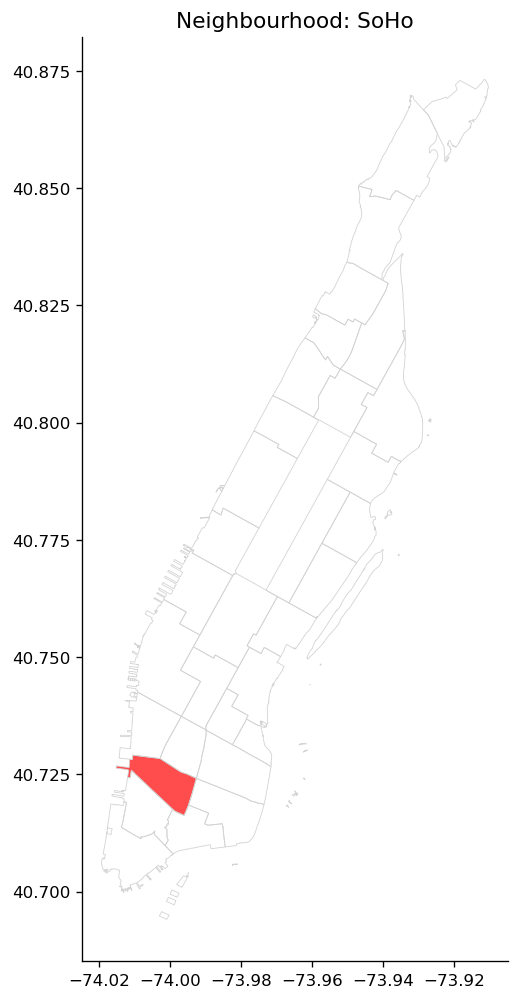

In [96]:
print(f"There are {n} restaurants in {nta_name}.")
show_neighbourhood_map("SoHo")

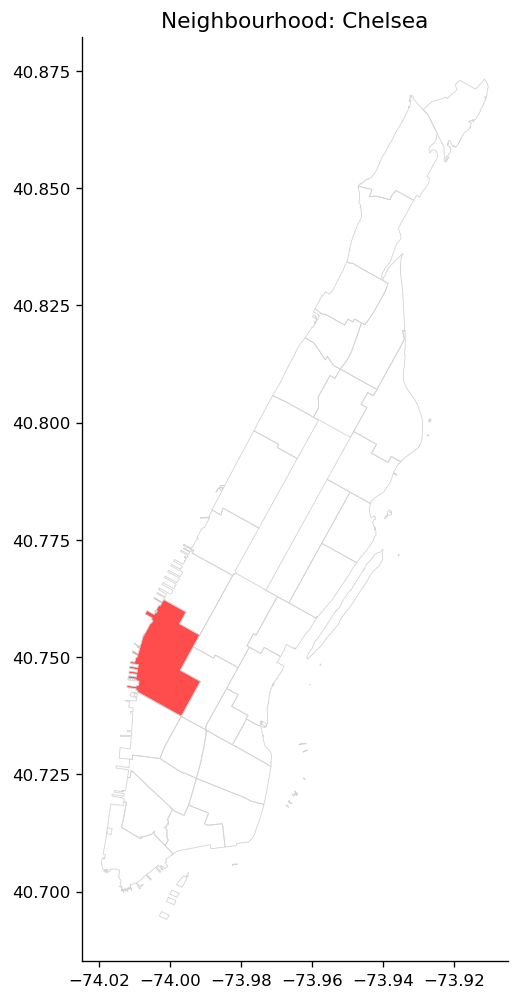

In [97]:
show_neighbourhood_map("Chelsea")

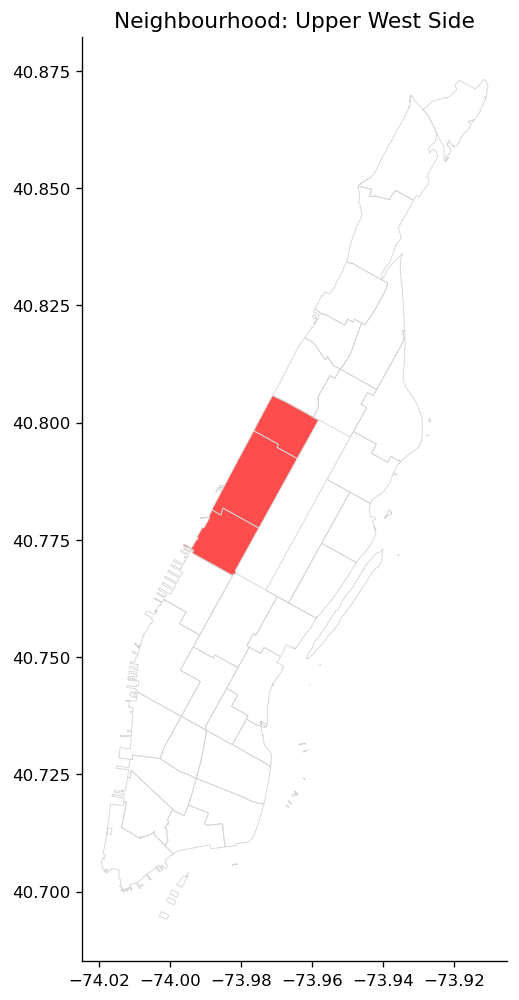

In [98]:
show_neighbourhood_map("Upper West Side")

In [99]:
def run_agent(query):

    print("Received:", query)

    q = query.lower()

    if "how many restaurants" in q:

        m = re.search(r"in (.+?)\??$", query)

        if m:

            neighbourhood = m.group(1).strip()

            nta_name, n = count_pois(
                category="restaurant",
                neighbourhood=neighbourhood,
                pois_gdf=pois_with_nta
            )

            print(
                f"Answer: There are {n} restaurants in {nta_name}."
            )

            show_neighbourhood_map(neighbourhood)

            return (
                f"There are {n} restaurants in {nta_name}."
            )

    return "I don't yet know how to answer that question."

Received: How many restaurants are there in SoHo?
Answer: There are 185 restaurants in SoHo-Little Italy-Hudson Square.


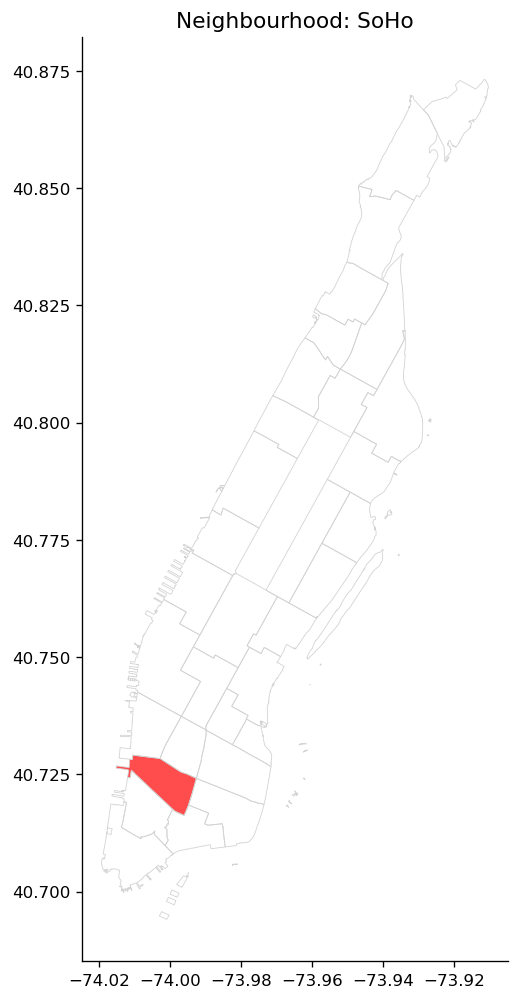

'There are 185 restaurants in SoHo-Little Italy-Hudson Square.'

In [100]:
run_agent("How many restaurants are there in SoHo?")

In [101]:
def show_restaurants_map(neighbourhood):

    nta_name, n = count_pois(
        category="restaurant",
        neighbourhood=neighbourhood,
        pois_gdf=pois_with_nta
    )

    restaurants = pois_with_nta[
        (pois_with_nta["element"] == "restaurant")
        &
        (pois_with_nta["ntaname"] == nta_name)
    ]

    nta = manhattan[
        manhattan["ntaname"] == nta_name
    ]

    fig, ax = plt.subplots(figsize=(10, 10))

    manhattan.boundary.plot(
        ax=ax,
        color="lightgrey"
    )

    nta.plot(
        ax=ax,
        color="lightblue",
        alpha=0.5
    )

    restaurants.plot(
        ax=ax,
        color="red",
        markersize=8
    )

    ax.set_title(
        f"{n} Restaurants in {nta_name}"
    )

    plt.show()

ValueError: aspect must be finite and positive 

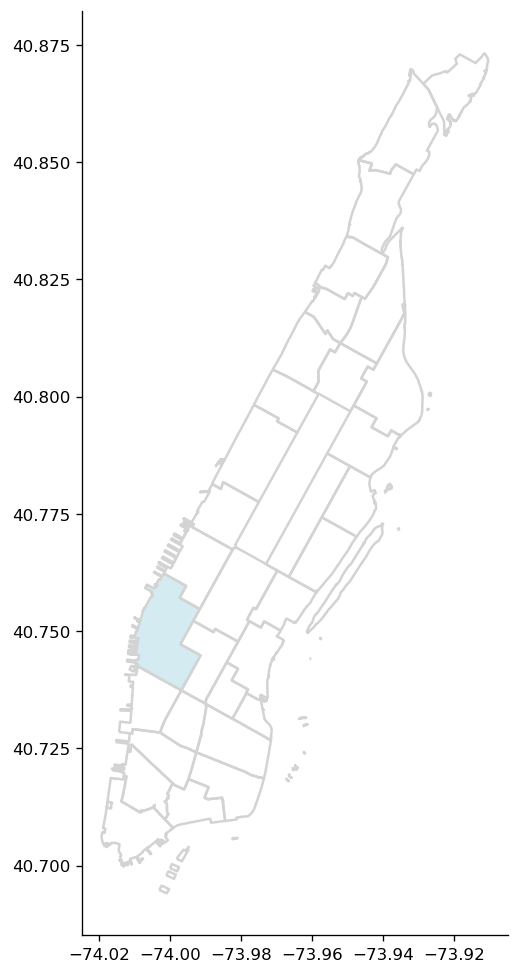

In [104]:
show_restaurants_map("Chelsea")

In [105]:
print(pois_with_nta.columns)

Index(['element', 'id', 'amenity', 'geometry', 'index_right', 'ntaname'], dtype='object')


In [106]:
nta_name, n = count_pois(
    category="restaurant",
    neighbourhood="Chelsea",
    pois_gdf=pois_with_nta
)

print("NTA Name:", nta_name)

restaurants = pois_with_nta[
    (pois_with_nta["amenity"] == "restaurant") &
    (pois_with_nta["ntaname"] == nta_name)
]

print("Restaurant records found:", len(restaurants))


NTA Name: Chelsea-Hudson Yards
Restaurant records found: 156


In [107]:
print(
    pois_with_nta["ntaname"]
    .dropna()
    .unique()[:20]
)

['Financial District-Battery Park City' 'Midtown-Times Square'
 'Washington Heights (South)' 'Chelsea-Hudson Yards' 'Harlem (North)'
 'East Village' 'Harlem (South)'
 'Upper East Side-Lenox Hill-Roosevelt Island'
 'Upper West Side-Lincoln Square' 'Chinatown-Two Bridges'
 'Murray Hill-Kips Bay' 'East Midtown-Turtle Bay' 'East Harlem (South)'
 'Upper East Side-Carnegie Hill' 'SoHo-Little Italy-Hudson Square'
 'Upper West Side (Central)' 'Tribeca-Civic Center' 'West Village'
 "Hell's Kitchen" 'Hamilton Heights-Sugar Hill']


In [108]:
pois_with_nta[
    pois_with_nta["ntaname"].str.contains(
        "Chelsea",
        case=False,
        na=False
    )
].head()

,element,id,amenity,geometry,index_right,ntaname
8,node,357561095,school,POINT (-74.00472 40.74528),8.0,Chelsea-Hudson Yards
131,node,357621536,school,POINT (-74.00269 40.74276),8.0,Chelsea-Hudson Yards
147,node,357621884,school,POINT (-74.00501 40.74669),8.0,Chelsea-Hudson Yards
228,node,368051665,theatre,POINT (-74.00151 40.74395),8.0,Chelsea-Hudson Yards
230,node,368051674,theatre,POINT (-74.00111 40.7425),8.0,Chelsea-Hudson Yards


In [109]:
def show_restaurants_map(neighbourhood):

    nta_name, n = count_pois(
        category="restaurant",
        neighbourhood=neighbourhood,
        pois_gdf=pois_with_nta
    )

    print(f"NTA: {nta_name}")
    print(f"Restaurants: {n}")

    restaurants = pois_with_nta[
        (pois_with_nta["amenity"] == "restaurant") &
        (pois_with_nta["ntaname"] == nta_name)
    ]

    print("Rows returned:", len(restaurants))

    if restaurants.empty:
        print("No restaurant points found.")
        return

    nta = manhattan[
        manhattan["ntaname"] == nta_name
    ]

    fig, ax = plt.subplots(figsize=(10, 10))

    manhattan.boundary.plot(
        ax=ax,
        color="lightgrey"
    )

    nta.plot(
        ax=ax,
        color="lightblue",
        alpha=0.5
    )

    restaurants.plot(
        ax=ax,
        color="red",
        markersize=12
    )

    ax.set_title(
        f"{n} Restaurants in {nta_name}"
    )

    plt.show()

NTA: Chelsea-Hudson Yards
Restaurants: 156
Rows returned: 156


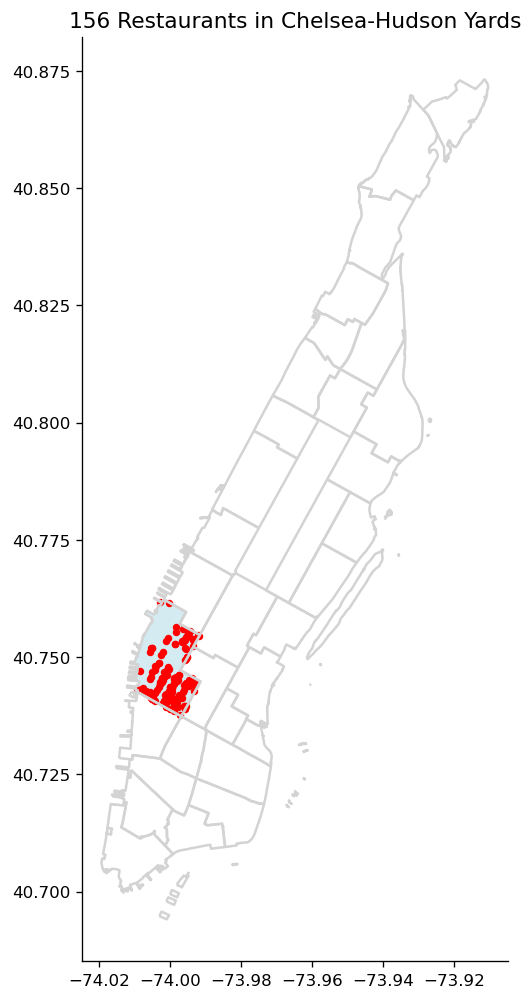

In [110]:
show_restaurants_map("Chelsea")

In [111]:
print("NTA:", nta_name)
print("Rows:", len(restaurants))

NTA: Chelsea-Hudson Yards
Rows: 156


In [112]:
print(restaurants.crs)
print(restaurants.geometry.head())
print(restaurants.geometry.isna().sum())

EPSG:4326
2174    POINT (-73.99355 40.75244)
2463    POINT (-74.00484 40.74216)
2533    POINT (-73.99581 40.75372)
2534    POINT (-73.99543 40.75426)
2535    POINT (-73.99534 40.75438)
Name: geometry, dtype: geometry
0


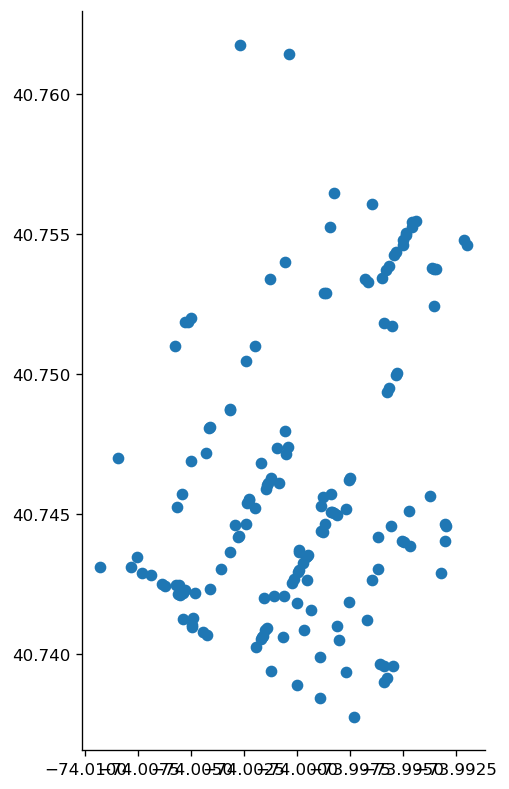

In [113]:
restaurants.plot(figsize=(8,8))
plt.show()

In [114]:
def show_restaurants_map(neighbourhood):

    nta_name, n = count_pois(
        category="restaurant",
        neighbourhood=neighbourhood,
        pois_gdf=pois_with_nta
    )

    restaurants = pois_with_nta[
        (pois_with_nta["amenity"] == "restaurant") &
        (pois_with_nta["ntaname"] == nta_name)
    ].copy()

    # Remove missing geometries
    restaurants = restaurants[
        restaurants.geometry.notnull()
    ]

    print(f"NTA: {nta_name}")
    print(f"Restaurant points: {len(restaurants)}")

    if len(restaurants) == 0:
        print("No restaurant points found.")
        return

    fig, ax = plt.subplots(figsize=(10,10))

    manhattan.boundary.plot(
        ax=ax,
        color="lightgrey",
        linewidth=0.5
    )

    nta = manhattan[
        manhattan["ntaname"] == nta_name
    ]

    if not nta.empty:
        nta.plot(
            ax=ax,
            color="lightblue",
            alpha=0.5
        )

    # Plot x/y explicitly
    ax.scatter(
        restaurants.geometry.x,
        restaurants.geometry.y,
        c="red",
        s=10,
        label="Restaurants"
    )

    plt.title(f"{n} Restaurants in {nta_name}")
    plt.legend()
    plt.show()

NTA: Chelsea-Hudson Yards
Restaurant points: 156


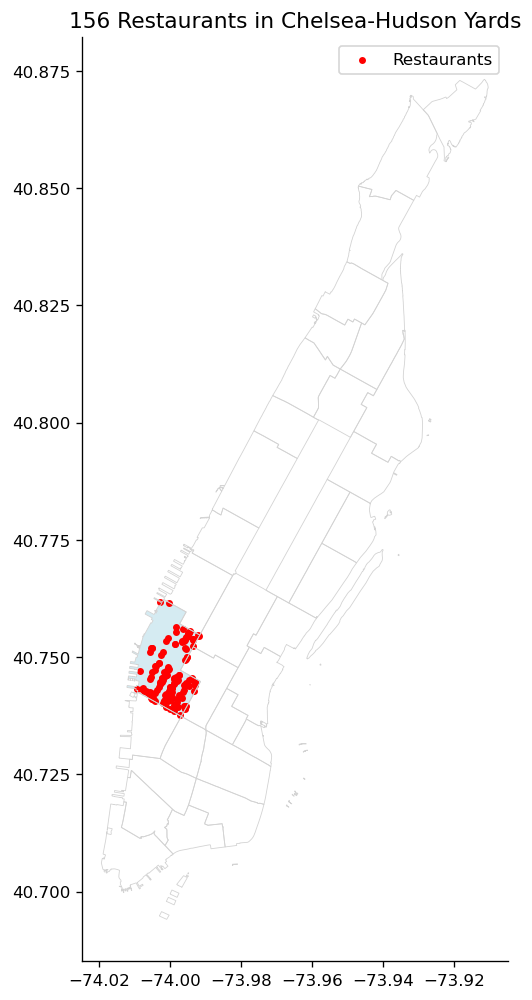

In [115]:
show_restaurants_map("Chelsea")

In [116]:
m = restaurant_map("Chelsea")
m

KeyError: 'category'

<Axes: >

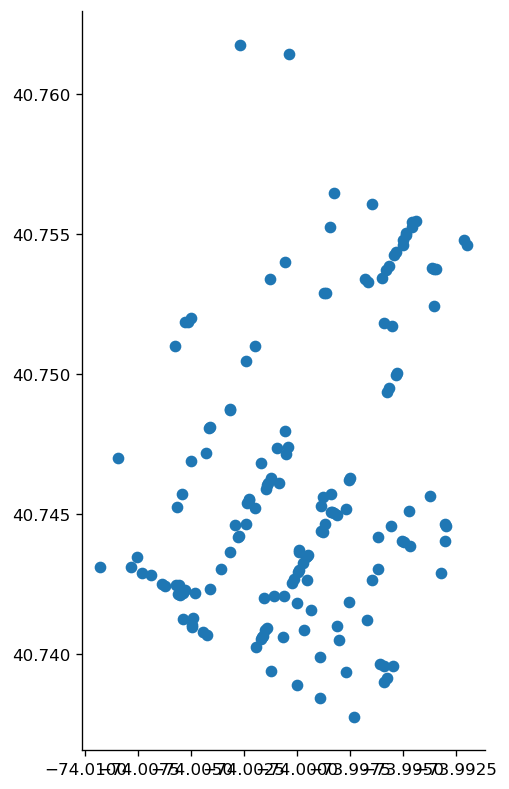

In [117]:
restaurants.plot(figsize=(8,8))

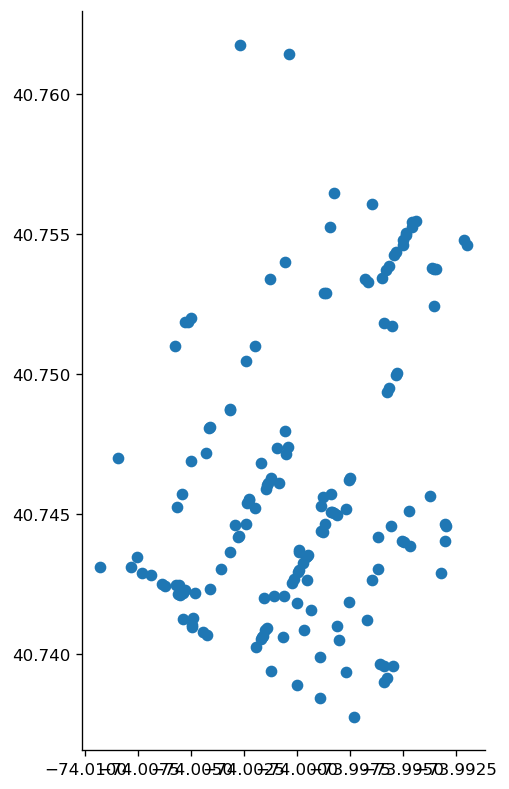

In [118]:
restaurants.plot(figsize=(8,8))
plt.show()

In [119]:
def show_restaurants_map(neighbourhood):

    nta_name, n = count_pois(
        category="restaurant",
        neighbourhood=neighbourhood,
        pois_gdf=pois_with_nta
    )

    restaurants = pois_with_nta[
        (pois_with_nta["amenity"] == "restaurant") &
        (pois_with_nta["ntaname"] == nta_name)
    ].copy()

    nta = manhattan[
        manhattan["ntaname"] == nta_name
    ]

    fig, ax = plt.subplots(figsize=(10,10))

    # Plot all neighbourhood boundaries
    manhattan.boundary.plot(
        ax=ax,
        color="lightgrey",
        linewidth=0.5
    )

    # Highlight selected neighbourhood
    if len(nta) > 0:
        nta.plot(
            ax=ax,
            color="lightblue",
            alpha=0.5
        )

    # Plot restaurant points using scatter
    ax.scatter(
        restaurants.geometry.x,
        restaurants.geometry.y,
        color="red",
        s=10,
        label="Restaurants"
    )

    ax.set_title(
        f"{n} Restaurants in {nta_name}"
    )

    ax.legend()

    plt.show()

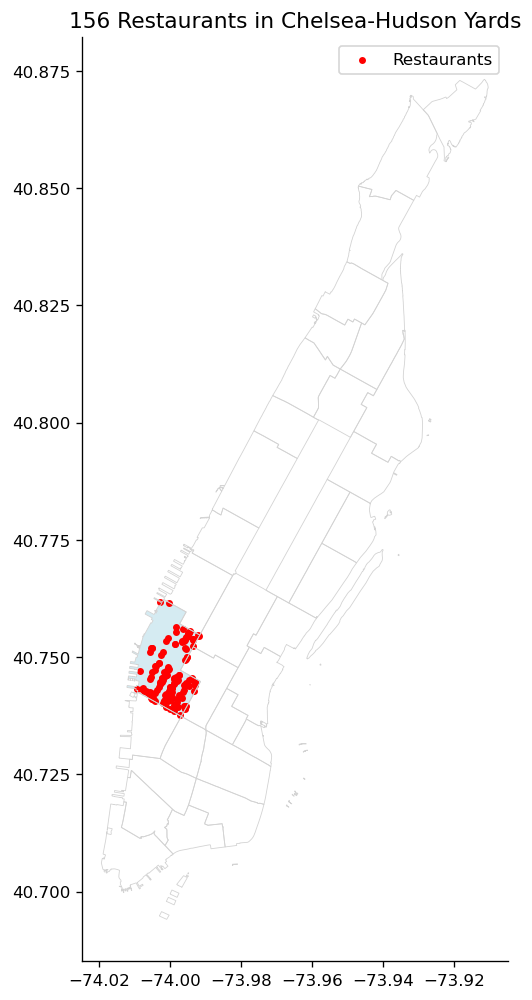

In [120]:
show_restaurants_map("Chelsea")

In [121]:
print(f"There are {n} restaurants in {nta_name}.")
show_restaurants_map(neighbourhood)

There are 156 restaurants in Chelsea-Hudson Yards.


NameError: name 'neighbourhood' is not defined

Received: How many restaurants are there in Chelsea?
Answer: There are 156 restaurants in Chelsea-Hudson Yards.


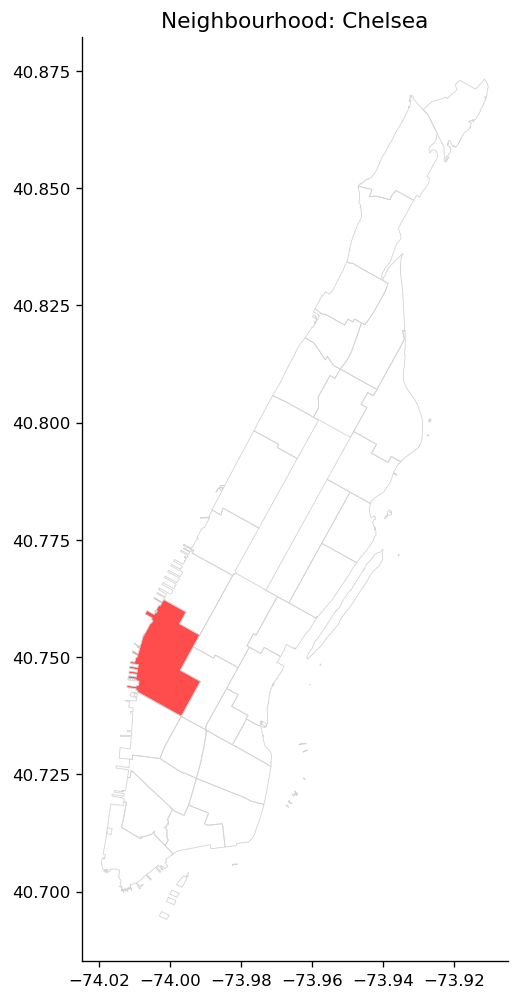

'There are 156 restaurants in Chelsea-Hudson Yards.'

In [122]:
run_agent("How many restaurants are there in Chelsea?")

In [123]:
m = restaurant_map("Chelsea")
m

KeyError: 'category'

In [124]:
import folium

def restaurant_map(neighbourhood):

    nta_name, n = count_pois(
        category="restaurant",
        neighbourhood=neighbourhood,
        pois_gdf=pois_with_nta
    )

    restaurants = pois_with_nta[
        (pois_with_nta["amenity"] == "restaurant") &
        (pois_with_nta["ntaname"] == nta_name)
    ].copy()

    if restaurants.empty:
        print("No restaurants found.")
        return None

    centre = restaurants.geometry.unary_union.centroid

    m = folium.Map(
        location=[centre.y, centre.x],
        zoom_start=14
    )

    for _, row in restaurants.iterrows():

        folium.CircleMarker(
            location=[
                row.geometry.y,
                row.geometry.x
            ],
            radius=3,
            color="red",
            fill=True,
            fill_opacity=0.8,
            popup=row["amenity"]
        ).add_to(m)

    return m

In [125]:
m = restaurant_map("Chelsea")
m

In [126]:
restaurants = pois_with_nta[
    (pois_with_nta["amenity"] == "restaurant") &
    (pois_with_nta["ntaname"] == "Chelsea-Hudson Yards")
]

print(len(restaurants))


156


In [127]:
folium.GeoJson(
    nta.__geo_interface__,
    style_function=lambda x: {
        "fillColor": "lightblue",
        "color": "blue",
        "weight": 2,
        "fillOpacity": 0.3
    }
).add_to(m)

NameError: name 'nta' is not defined

In [128]:
import folium

def restaurant_map(neighbourhood):

    nta_name, n = count_pois(
        category="restaurant",
        neighbourhood=neighbourhood,
        pois_gdf=pois_with_nta
    )

    restaurants = pois_with_nta[
        (pois_with_nta["amenity"] == "restaurant") &
        (pois_with_nta["ntaname"] == nta_name)
    ].copy()

    if restaurants.empty:
        print("No restaurants found.")
        return None

    centre = restaurants.geometry.unary_union.centroid

    m = folium.Map(
        location=[centre.y, centre.x],
        zoom_start=14
    )

    for _, row in restaurants.iterrows():

        folium.CircleMarker(
            location=[
                row.geometry.y,
                row.geometry.x
            ],
            radius=3,
            color="red",
            fill=True,
            fill_opacity=0.8,
            popup=row["amenity"]
        ).add_to(m)

    return m

In [129]:
m = restaurant_map("Chelsea")
m

In [130]:
restaurants = pois_with_nta[
    (pois_with_nta["amenity"] == "restaurant") &
    (pois_with_nta["ntaname"] == "Chelsea-Hudson Yards")
]

print(len(restaurants))

156


In [131]:
folium.GeoJson(
    nta.__geo_interface__,
    style_function=lambda x: {
        "fillColor": "lightblue",
        "color": "blue",
        "weight": 2,
        "fillOpacity": 0.3
    }
).add_to(m)

NameError: name 'nta' is not defined

In [132]:
import folium

def restaurant_map(neighbourhood):

    nta_name, n = count_pois(
        category="restaurant",
        neighbourhood=neighbourhood,
        pois_gdf=pois_with_nta
    )

    # NTA polygon
    nta = manhattan[
        manhattan["ntaname"] == nta_name
    ]

    # Restaurant points
    restaurants = pois_with_nta[
        (pois_with_nta["amenity"] == "restaurant") &
        (pois_with_nta["ntaname"] == nta_name)
    ]

    if restaurants.empty:
        print("No restaurants found.")
        return None

    # Centre map
    centre = restaurants.geometry.unary_union.centroid

    m = folium.Map(
        location=[centre.y, centre.x],
        zoom_start=14
    )

    # Add neighbourhood boundary
    if not nta.empty:
        folium.GeoJson(
            nta.__geo_interface__,
            style_function=lambda x: {
                "fillColor": "lightblue",
                "color": "blue",
                "weight": 2,
                "fillOpacity": 0.3
            }
        ).add_to(m)

    # Add restaurant points
    for _, row in restaurants.iterrows():
        folium.CircleMarker(
            location=[row.geometry.y, row.geometry.x],
            radius=3,
            color="red",
            fill=True,
            fill_opacity=0.8
        ).add_to(m)

    return m

In [133]:
m = restaurant_map("Chelsea")
m

In [134]:
restaurant_map("SoHo")

In [137]:
import re
from IPython.display import display

def run_agent(query):

    q = query.lower()

    if "how many restaurants" in q:

        m = re.search(r"in (.+?)\??$", query)

        if m:

            neighbourhood = m.group(1).strip()

            nta_name, n = count_pois(
                category="restaurant",
                neighbourhood=neighbourhood,
                pois_gdf=pois_with_nta
            )

            print(f"Answer: There are {n} restaurants in {nta_name}.")

            # Display interactive map
            mapp = restaurant_map(neighbourhood)

            if mapp is not None:
                display(mapp)

            return f"There are {n} restaurants in {nta_name}."

    return "I don't yet know how to answer that question."
      

In [138]:
run_agent("How many restaurants are there in Chelsea?")

Answer: There are 156 restaurants in Chelsea-Hudson Yards.


'There are 156 restaurants in Chelsea-Hudson Yards.'

In [139]:
import folium

def restaurant_map(neighbourhood):

    nta_name, n = count_pois(
        category="restaurant",
        neighbourhood=neighbourhood,
        pois_gdf=pois_with_nta
    )

    nta = manhattan[
        manhattan["ntaname"] == nta_name
    ]

    restaurants = pois_with_nta[
        (pois_with_nta["amenity"] == "restaurant") &
        (pois_with_nta["ntaname"] == nta_name)
    ].copy()

    if restaurants.empty:
        print("No restaurants found.")
        return None

    centre = restaurants.geometry.unary_union.centroid

    m = folium.Map(
        location=[centre.y, centre.x],
        zoom_start=14
    )

    # Neighbourhood boundary
    if not nta.empty:
        folium.GeoJson(
            nta.__geo_interface__,
            style_function=lambda x: {
                "fillColor": "lightblue",
                "color": "blue",
                "weight": 2,
                "fillOpacity": 0.3
            }
        ).add_to(m)

    # Restaurant points
    for _, row in restaurants.iterrows():

        # Use name column if available
        name = row.get("name", "Restaurant")

        folium.CircleMarker(
            location=[row.geometry.y, row.geometry.x],
            radius=4,
            color="red",
            fill=True,
            fill_opacity=0.8,
            popup=name
        ).add_to(m)

    return m

In [140]:
print(pois_with_nta.columns)

Index(['element', 'id', 'amenity', 'geometry', 'index_right', 'ntaname'], dtype='object')


In [141]:
pois_with_nta.head()

,element,id,amenity,geometry,index_right,ntaname
0,node,166878947,ferry_terminal,POINT (-74.0055 40.70245),0.0,Financial District-Battery Park City
1,node,291921307,drinking_water,POINT (-73.95821 40.79943),NaN,NaN
2,node,291921309,drinking_water,POINT (-73.95537 40.79287),NaN,NaN
3,node,291921311,drinking_water,POINT (-73.95563 40.7922),NaN,NaN
4,node,322546340,toilets,POINT (-73.97123 40.77352),NaN,NaN


In [142]:
popup=f"Restaurant ID: {row['id']}"

NameError: name 'row' is not defined

In [143]:
import re
from IPython.display import display

def run_agent(query):

    q = query.lower()

    # COUNT RESTAURANTS
    if "how many restaurants" in q:

        m = re.search(r"in (.+?)\??$", query)

        if m:

            neighbourhood = m.group(1).strip()

            nta_name, n = count_pois(
                category="restaurant",
                neighbourhood=neighbourhood,
                pois_gdf=pois_with_nta
            )

            print(f"There are {n} restaurants in {nta_name}.")

            display(restaurant_map(neighbourhood))

            return f"There are {n} restaurants in {nta_name}."

    # SHOW RESTAURANTS
    if "show restaurants" in q:

        m = re.search(r"in (.+?)\??$", query)

        if m:

            neighbourhood = m.group(1).strip()

            display(restaurant_map(neighbourhood))

            return f"Showing restaurants in {neighbourhood}."

    return "I don't yet know how to answer that question."

In [144]:
import folium

def restaurant_map(neighbourhood):

    nta_name, n = count_pois(
        category="restaurant",
        neighbourhood=neighbourhood,
        pois_gdf=pois_with_nta
    )

    nta = manhattan[
        manhattan["ntaname"] == nta_name
    ]

    restaurants = pois_with_nta[
        (pois_with_nta["amenity"] == "restaurant") &
        (pois_with_nta["ntaname"] == nta_name)
    ]

    if restaurants.empty:
        return None

    centre = restaurants.geometry.unary_union.centroid

    m = folium.Map(
        location=[centre.y, centre.x],
        zoom_start=14
    )

    # Neighborhood polygon
    if not nta.empty:
        folium.GeoJson(
            nta.__geo_interface__,
            style_function=lambda x: {
                "fillColor": "lightblue",
                "color": "blue",
                "weight": 2,
                "fillOpacity": 0.3
            }
        ).add_to(m)

    # Restaurant locations
    for _, row in restaurants.iterrows():

        folium.CircleMarker(
            location=[
                row.geometry.y,
                row.geometry.x
            ],
            radius=4,
            color="red",
            fill=True,
            popup=f"Restaurant ID: {row['id']}"
        ).add_to(m)

    return m

In [145]:
run_agent("Show restaurants in Chelsea")

'Showing restaurants in Chelsea.'

In [146]:
run_agent("Show restaurants in SoHo")

'Showing restaurants in SoHo.'

In [147]:
print(pois.head())

  element         id         amenity                    geometry
0    node  166878947  ferry_terminal   POINT (-74.0055 40.70245)
1    node  291921307  drinking_water  POINT (-73.95821 40.79943)
2    node  291921309  drinking_water  POINT (-73.95537 40.79287)
3    node  291921311  drinking_water   POINT (-73.95563 40.7922)
4    node  322546340         toilets  POINT (-73.97123 40.77352)


In [148]:
print(pois.columns)

Index(['element', 'id', 'amenity', 'geometry'], dtype='object')


In [149]:
for _, row in restaurants.iterrows():

    folium.CircleMarker(
        location=[row.geometry.y, row.geometry.x],
        radius=4,
        color="red",
        fill=True,
        fill_opacity=0.8,
        popup=f"OSM ID: {row['id']}"
    ).add_to(m)

In [150]:
import re
from IPython.display import display

def run_agent(query):

    q = query.lower()

    # Count restaurants
    if "how many restaurants" in q:

        m = re.search(r"in (.+?)\??$", query)

        if m:

            neighbourhood = m.group(1).strip()

            nta_name, n = count_pois(
                category="restaurant",
                neighbourhood=neighbourhood,
                pois_gdf=pois_with_nta
            )

            display(restaurant_map(neighbourhood))

            return (
                f"There are {n} restaurants in {nta_name}."
            )

    # Show restaurants
    elif "show restaurants" in q:

        m = re.search(r"in (.+?)\??$", query)

        if m:

            neighbourhood = m.group(1).strip()

            display(
                restaurant_map(neighbourhood)
            )

            return (
                f"Showing restaurants in "
                f"{neighbourhood}."
            )

    return "I don't yet know how to answer that question."

In [151]:
run_agent("Show restaurants in Chelsea")

'Showing restaurants in Chelsea.'

In [152]:
run_agent("Show restaurants in SoHo")

'Showing restaurants in SoHo.'

In [153]:
run_agent("How many restaurants are there in Harlem?")

'There are 176 restaurants in Harlem (South).'

In [155]:
VALID_CATEGORIES = set(
    pois_with_nta["amenity"]
    .dropna()
    .unique()
)

In [156]:
sorted(list(VALID_CATEGORIES))[:50]

['School Supply Store',
 'animal_boarding',
 'animal_shelter',
 'arts_centre',
 'atm',
 'bank',
 'bar',
 'bbq',
 'bench',
 'bicycle_parking',
 'bicycle_rental',
 'bicycle_repair_station',
 'biergarten',
 'binoculars',
 'boat_rental',
 'brewery',
 'bureau_de_change',
 'bus_station',
 'cafe',
 'cafe;bar',
 'car_rental',
 'car_sharing',
 'car_wash',
 'charging_station',
 'childcare',
 'cinema',
 'clear',
 'clinic',
 'clock',
 'college',
 'community_centre',
 'compressed_air',
 'conference_centre',
 'convenience',
 'courthouse',
 'coworking_space',
 'dance_school',
 'dancing_school',
 'dentist',
 'device_charging_station',
 'disused',
 'doctors',
 'dojo',
 'dormitory',
 'drinking_water',
 'driving_school',
 'events_venue',
 'fast_food',
 'ferry_terminal',
 'fire_station']

In [157]:
import folium

def amenity_map(category, neighbourhood):

    nta_name, n = count_pois(
        category=category,
        neighbourhood=neighbourhood,
        pois_gdf=pois_with_nta
    )

    nta = manhattan[
        manhattan["ntaname"] == nta_name
    ]

    places = pois_with_nta[
        (pois_with_nta["amenity"] == category) &
        (pois_with_nta["ntaname"] == nta_name)
    ]

    if places.empty:
        print("No locations found.")
        return None

    centre = places.geometry.unary_union.centroid

    m = folium.Map(
        location=[centre.y, centre.x],
        zoom_start=14
    )

    if not nta.empty:

        folium.GeoJson(
            nta.__geo_interface__,
            style_function=lambda x: {
                "fillColor": "lightblue",
                "color": "blue",
                "weight": 2,
                "fillOpacity": 0.3
            }
        ).add_to(m)

    for _, row in places.iterrows():

        folium.CircleMarker(
            location=[
                row.geometry.y,
                row.geometry.x
            ],
            radius=4,
            color="red",
            fill=True,
            popup=f"{category} (ID {row['id']})"
        ).add_to(m)

    return m

In [158]:
def find_category(query):

    q = query.lower()

    for cat in VALID_CATEGORIES:

        if str(cat).lower() in q:
            return cat

    return None

In [159]:
import re
from IPython.display import display

def run_agent(query):

    q = query.lower()

    category = find_category(query)

    #
    # COUNT QUERY
    #
    if "how many" in q and category:

        m = re.search(r"in (.+?)\??$", query)

        if m:

            neighbourhood = m.group(1).strip()

            nta_name, n = count_pois(
                category=category,
                neighbourhood=neighbourhood,
                pois_gdf=pois_with_nta
            )

            display(
                amenity_map(
                    category,
                    neighbourhood
                )
            )

            return (
                f"There are {n} "
                f"{category}s in "
                f"{nta_name}."
            )

    #
    # SHOW QUERY
    #
    if "show" in q and category:

        m = re.search(r"in (.+?)\??$", query)

        if m:

            neighbourhood = m.group(1).strip()

            display(
                amenity_map(
                    category,
                    neighbourhood
                )
            )

            return (
                f"Showing {category}s "
                f"in {neighbourhood}."
            )

    #
    # RANKING QUERY
    #
    if "most" in q and category:

        return rank_neighbourhoods(category)

    #
    # SOHO DESCRIPTION
    #
    if "what kind of neighbourhood" in q:

        m = re.search(r"is (.+?)\??$", query)

        if m:

            neighbourhood = m.group(1).strip()

            return summarise_neighbourhood_simple(
                neighbourhood
            )

    #
    # FINANCIAL DISTRICT NEARBY
    #
    if "nearby" in q or "within 1 km" in q:

        return nearby_food(
            40.706,
            -74.011,
            1000
        )

    return (
        "I don't yet know how to "
        "answer that question."
    )

In [160]:
run_agent(
    "How many restaurants are there in Chelsea?"
)

'There are 156 restaurants in Chelsea-Hudson Yards.'

In [161]:
run_agent(
    "How many cafes are there in Harlem?"
)

'There are 38 cafes in Harlem (North).'

In [162]:
run_agent(
    "How many bars are there in SoHo?"
)

'There are 26 bars in SoHo-Little Italy-Hudson Square.'

In [163]:
run_agent(
    "Show restaurants in Chelsea"
)

'Showing restaurants in Chelsea.'

In [164]:
run_agent(
    "Which neighbourhood has the most restaurants?"
)

ntaname
Midtown-Times Square                           324
East Village                                   267
Midtown South-Flatiron-Union Square            215
SoHo-Little Italy-Hudson Square                185
Hell's Kitchen                                 180
West Village                                   168
Chinatown-Two Bridges                          159
Chelsea-Hudson Yards                           156
Financial District-Battery Park City           154
Greenwich Village                              146
Upper West Side (Central)                      142
Lower East Side                                133
East Midtown-Turtle Bay                        122
Upper East Side-Carnegie Hill                  115
Upper East Side-Lenox Hill-Roosevelt Island    106
Murray Hill-Kips Bay                           100
Upper East Side-Yorkville                       96
Tribeca-Civic Center                            84
Upper West Side-Manhattan Valley                77
Gramercy               

In [165]:
run_agent(
    "Which neighbourhood has the most cafes?"
)

ntaname
Midtown-Times Square                           140
Financial District-Battery Park City            83
East Village                                    82
Midtown South-Flatiron-Union Square             74
SoHo-Little Italy-Hudson Square                 73
Chelsea-Hudson Yards                            68
Greenwich Village                               63
Upper West Side (Central)                       54
Upper East Side-Carnegie Hill                   53
West Village                                    52
Murray Hill-Kips Bay                            49
East Midtown-Turtle Bay                         47
Chinatown-Two Bridges                           46
Hell's Kitchen                                  43
Upper East Side-Lenox Hill-Roosevelt Island     40
Lower East Side                                 38
Tribeca-Civic Center                            37
Gramercy                                        30
Upper West Side-Lincoln Square                  29
Upper East Side-Yorkvil

In [167]:
run_agent(
    "What kind of neighbourhood is SoHo?"
)

In [169]:
summarise_neighbourhood_simple("SoHo")

In [176]:
import re
from IPython.display import display

def run_agent(query):

    q = query.lower()

    category = find_category(query)

    # COUNT QUERY
    if "how many" in q and category:

        m = re.search(r"in (.+?)\??$", query)

        if m:

            neighbourhood = m.group(1).strip()

            nta_name, n = count_pois(
                category=category,
                neighbourhood=neighbourhood,
                pois_gdf=pois_with_nta
            )

            display(
                amenity_map(
                    category,
                    neighbourhood
                )
            )

            return (
                f"There are {n} {category}s in "
                f"{nta_name}."
            )

    # SHOW QUERY
    elif "show" in q and category:

        m = re.search(r"in (.+?)\??$", query)

        if m:

            neighbourhood = m.group(1).strip()

            display(
                amenity_map(
                    category,
                    neighbourhood
                )
            )

            return (
                f"Showing {category}s in "
                f"{neighbourhood}."
            )

    # RANK QUERY
    elif "most" in q and category:

        return rank_neighbourhoods(category)

    # DESCRIBE NEIGHBOURHOOD
    elif (
        "what kind of neighbourhood" in q
        or "describe" in q
        or "tell me about" in q
    ):

        m = re.search(
            r"(?:is|about)\s+(.+?)\??$",
            query,
            re.IGNORECASE
        )

        if m:

            neighbourhood = m.group(1).strip()

            return summarise_neighbourhood_simple(
                neighbourhood
            )

    # NEARBY FOOD
    elif (
        "nearby" in q
        or "within 1 km" in q
        or "food options" in q
    ):

        return nearby_food(
            40.706,
            -74.011,
            1000
        )

    return "I don't yet know how to answer that question."

In [177]:
run_agent("What kind of neighbourhood is SoHo?")

In [178]:
run_agent("Describe Chelsea")

"I don't yet know how to answer that question."

In [179]:
run_agent("How many cafes are there in Chelsea?")

'There are 68 cafes in Chelsea-Hudson Yards.'

In [180]:
summarise_neighbourhood_simple("SoHo")

In [181]:
import inspect
print(inspect.getsource(summarise_neighbourhood_simple))

def summarise_neighbourhood_simple(neighbourhood):

    subset = pois_with_nta[
        pois_with_nta["ntaname"]
        .str.contains(neighbourhood,
                      case=False,
                      na=False)
    ]

    if len(subset) == 0:
        return "Neighbourhood not found."

    top = subset["amenity"].value_counts().head(10)



In [182]:
summarise_neighbourhood_simple("SoHo")

In [183]:
import inspect
print(inspect.getsource(summarise_neighbourhood_simple))

def summarise_neighbourhood_simple(neighbourhood):

    subset = pois_with_nta[
        pois_with_nta["ntaname"]
        .str.contains(neighbourhood,
                      case=False,
                      na=False)
    ]

    if len(subset) == 0:
        return "Neighbourhood not found."

    top = subset["amenity"].value_counts().head(10)



In [184]:
def summarise_neighbourhood_simple(neighbourhood):

    subset = pois_with_nta[
        pois_with_nta["ntaname"]
        .str.contains(
            neighbourhood,
            case=False,
            na=False
        )
    ]

    if len(subset) == 0:
        return "Neighbourhood not found."

    top = subset["amenity"].value_counts().head(10)

    summary = (
        f"{neighbourhood} contains "
        f"{len(subset)} mapped amenities. "
        f"The most common amenities are:\n\n"
    )

    for amenity, count in top.items():
        summary += f"• {amenity}: {count}\n"

    return summary

In [185]:
print(
    summarise_neighbourhood_simple("SoHo")
)

SoHo contains 937 mapped amenities. The most common amenities are:

• bicycle_parking: 218
• restaurant: 185
• bench: 121
• waste_basket: 95
• cafe: 73
• fast_food: 37
• bar: 26
• post_box: 22
• bank: 22
• bicycle_rental: 19



In [186]:
def summarise_neighbourhood_simple(neighbourhood):

    subset = pois_with_nta[
        pois_with_nta["ntaname"]
        .str.contains(
            neighbourhood,
            case=False,
            na=False
        )
    ]

    if subset.empty:
        return "Neighbourhood not found."

    total = len(subset)

    restaurants = (
        subset["amenity"] == "restaurant"
    ).sum()

    cafes = (
        subset["amenity"] == "cafe"
    ).sum()

    bars = (
        subset["amenity"] == "bar"
    ).sum()

    top = subset["amenity"].value_counts().head(5)

    text = (
        f"{neighbourhood} contains "
        f"{total} mapped amenities.\n\n"
        f"Restaurants: {restaurants}\n"
        f"Cafes: {cafes}\n"
        f"Bars: {bars}\n\n"
        f"Top amenity categories:\n"
    )

    for amenity, count in top.items():
        text += f"- {amenity}: {count}\n"

    return text

In [187]:
count_pois(
    category="restaurant",
    neighbourhood="Chelsea",
    pois_gdf=pois_with_nta
)

('Chelsea-Hudson Yards', 156)

In [188]:
amenity_map(
    category="restaurant",
    neighbourhood="Chelsea"
)

In [189]:
amenity_map(
    category="restaurant",
    neighbourhood="Chelsea"
)

In [190]:
rank_neighbourhoods("restaurant")

ntaname
Midtown-Times Square                           324
East Village                                   267
Midtown South-Flatiron-Union Square            215
SoHo-Little Italy-Hudson Square                185
Hell's Kitchen                                 180
West Village                                   168
Chinatown-Two Bridges                          159
Chelsea-Hudson Yards                           156
Financial District-Battery Park City           154
Greenwich Village                              146
Upper West Side (Central)                      142
Lower East Side                                133
East Midtown-Turtle Bay                        122
Upper East Side-Carnegie Hill                  115
Upper East Side-Lenox Hill-Roosevelt Island    106
Murray Hill-Kips Bay                           100
Upper East Side-Yorkville                       96
Tribeca-Civic Center                            84
Upper West Side-Manhattan Valley                77
Gramercy               

In [191]:
summarise_neighbourhood_simple("SoHo")

'SoHo contains 937 mapped amenities.\n\nRestaurants: 185\nCafes: 73\nBars: 26\n\nTop amenity categories:\n- bicycle_parking: 218\n- restaurant: 185\n- bench: 121\n- waste_basket: 95\n- cafe: 73\n'

In [192]:
nearby_food(
    40.706,
    -74.011,
    1000
)

(      element           id     amenity                       geometry  \
 2812     node   2183010450  restaurant  POINT (981187.243 196537.235)   
 2813     node   2183010451  restaurant  POINT (981175.948 195574.458)   
 2836     node   2183891964  restaurant  POINT (981645.963 196541.918)   
 2840     node   2183891975  restaurant  POINT (982106.106 196344.916)   
 2841     node   2183891976  restaurant  POINT (981563.271 196166.739)   
 2843     node   2183891980  restaurant  POINT (982013.128 196200.832)   
 2847     node   2186614176  restaurant  POINT (981866.808 196087.758)   
 2848     node   2186614177  restaurant  POINT (981420.425 196142.455)   
 2850     node   2186614181  restaurant  POINT (981214.039 196197.421)   
 2851     node   2186614182  restaurant  POINT (981540.463 196003.486)   
 2852     node   2186614185  restaurant  POINT (981588.326 196073.978)   
 2854     node   2186614188  restaurant  POINT (981800.066 196043.644)   
 2857     node   2186614191  restauran

In [193]:
run_agent(
    "How many restaurants are there in Chelsea?"
)

'There are 156 restaurants in Chelsea-Hudson Yards.'

In [194]:
run_agent(
    "Show restaurants in SoHo"
)

'Showing restaurants in SoHo.'

In [195]:
run_agent(
    "Which neighbourhood has the most cafes?"
)

ntaname
Midtown-Times Square                           140
Financial District-Battery Park City            83
East Village                                    82
Midtown South-Flatiron-Union Square             74
SoHo-Little Italy-Hudson Square                 73
Chelsea-Hudson Yards                            68
Greenwich Village                               63
Upper West Side (Central)                       54
Upper East Side-Carnegie Hill                   53
West Village                                    52
Murray Hill-Kips Bay                            49
East Midtown-Turtle Bay                         47
Chinatown-Two Bridges                           46
Hell's Kitchen                                  43
Upper East Side-Lenox Hill-Roosevelt Island     40
Lower East Side                                 38
Tribeca-Civic Center                            37
Gramercy                                        30
Upper West Side-Lincoln Square                  29
Upper East Side-Yorkvil

In [196]:
run_agent(
    "What kind of neighbourhood is SoHo?"
)


'SoHo contains 937 mapped amenities.\n\nRestaurants: 185\nCafes: 73\nBars: 26\n\nTop amenity categories:\n- bicycle_parking: 218\n- restaurant: 185\n- bench: 121\n- waste_basket: 95\n- cafe: 73\n'

In [197]:
def summarise_neighbourhood_simple(neighbourhood):

    subset = ...

    if len(subset) == 0:
        return "Neighbourhood not found."

    top = subset["amenity"].value_counts().head(10)

In [198]:
def summarise_neighbourhood_simple(neighbourhood):

    subset = pois_with_nta[
        pois_with_nta["ntaname"]
        .str.contains(
            neighbourhood,
            case=False,
            na=False
        )
    ]

    if len(subset) == 0:
        return "Neighbourhood not found."

    top = subset["amenity"].value_counts().head(10)

    text = (
        f"{neighbourhood} contains "
        f"{len(subset)} mapped amenities.\n\n"
        f"Top amenity categories:\n"
    )

    for amenity, count in top.items():
        text += f"- {amenity}: {count}\n"

    return text

In [199]:
print(
    summarise_neighbourhood_simple("SoHo")
)

SoHo contains 937 mapped amenities.

Top amenity categories:
- bicycle_parking: 218
- restaurant: 185
- bench: 121
- waste_basket: 95
- cafe: 73
- fast_food: 37
- bar: 26
- post_box: 22
- bank: 22
- bicycle_rental: 19



In [200]:
nta_name, n = count_pois(
    category="restaurant",
    neighbourhood="Chelsea",
    pois_gdf=pois_with_nta
)

print(nta_name)
print(n)

Chelsea-Hudson Yards
156


In [201]:
m = amenity_map(
    category="restaurant",
    neighbourhood="Chelsea"
)

m

In [202]:
m = amenity_map(
    category="cafe",
    neighbourhood="SoHo"
)

m

In [203]:
rank_neighbourhoods("restaurant")

ntaname
Midtown-Times Square                           324
East Village                                   267
Midtown South-Flatiron-Union Square            215
SoHo-Little Italy-Hudson Square                185
Hell's Kitchen                                 180
West Village                                   168
Chinatown-Two Bridges                          159
Chelsea-Hudson Yards                           156
Financial District-Battery Park City           154
Greenwich Village                              146
Upper West Side (Central)                      142
Lower East Side                                133
East Midtown-Turtle Bay                        122
Upper East Side-Carnegie Hill                  115
Upper East Side-Lenox Hill-Roosevelt Island    106
Murray Hill-Kips Bay                           100
Upper East Side-Yorkville                       96
Tribeca-Civic Center                            84
Upper West Side-Manhattan Valley                77
Gramercy               

In [204]:
rank_neighbourhoods("cafe")

ntaname
Midtown-Times Square                           140
Financial District-Battery Park City            83
East Village                                    82
Midtown South-Flatiron-Union Square             74
SoHo-Little Italy-Hudson Square                 73
Chelsea-Hudson Yards                            68
Greenwich Village                               63
Upper West Side (Central)                       54
Upper East Side-Carnegie Hill                   53
West Village                                    52
Murray Hill-Kips Bay                            49
East Midtown-Turtle Bay                         47
Chinatown-Two Bridges                           46
Hell's Kitchen                                  43
Upper East Side-Lenox Hill-Roosevelt Island     40
Lower East Side                                 38
Tribeca-Civic Center                            37
Gramercy                                        30
Upper West Side-Lincoln Square                  29
Upper East Side-Yorkvil

In [205]:
print(
    summarise_neighbourhood_simple("SoHo")
)

SoHo contains 937 mapped amenities.

Top amenity categories:
- bicycle_parking: 218
- restaurant: 185
- bench: 121
- waste_basket: 95
- cafe: 73
- fast_food: 37
- bar: 26
- post_box: 22
- bank: 22
- bicycle_rental: 19



In [206]:
print(
    summarise_neighbourhood_simple("Chelsea")
)

Chelsea contains 1192 mapped amenities.

Top amenity categories:
- bicycle_parking: 259
- bench: 255
- restaurant: 156
- fast_food: 70
- cafe: 68
- waste_basket: 54
- bicycle_rental: 41
- bar: 40
- drinking_water: 28
- parking_entrance: 18



In [207]:
nearby_food(
    40.706,
    -74.011,
    1000
)

(      element           id     amenity                       geometry  \
 2812     node   2183010450  restaurant  POINT (981187.243 196537.235)   
 2813     node   2183010451  restaurant  POINT (981175.948 195574.458)   
 2836     node   2183891964  restaurant  POINT (981645.963 196541.918)   
 2840     node   2183891975  restaurant  POINT (982106.106 196344.916)   
 2841     node   2183891976  restaurant  POINT (981563.271 196166.739)   
 2843     node   2183891980  restaurant  POINT (982013.128 196200.832)   
 2847     node   2186614176  restaurant  POINT (981866.808 196087.758)   
 2848     node   2186614177  restaurant  POINT (981420.425 196142.455)   
 2850     node   2186614181  restaurant  POINT (981214.039 196197.421)   
 2851     node   2186614182  restaurant  POINT (981540.463 196003.486)   
 2852     node   2186614185  restaurant  POINT (981588.326 196073.978)   
 2854     node   2186614188  restaurant  POINT (981800.066 196043.644)   
 2857     node   2186614191  restauran

In [208]:
run_agent(
    "How many restaurants are there in Chelsea?"
)

'There are 156 restaurants in Chelsea-Hudson Yards.'

In [209]:
run_agent(
    "Which neighbourhood has the most restaurants?"
)

ntaname
Midtown-Times Square                           324
East Village                                   267
Midtown South-Flatiron-Union Square            215
SoHo-Little Italy-Hudson Square                185
Hell's Kitchen                                 180
West Village                                   168
Chinatown-Two Bridges                          159
Chelsea-Hudson Yards                           156
Financial District-Battery Park City           154
Greenwich Village                              146
Upper West Side (Central)                      142
Lower East Side                                133
East Midtown-Turtle Bay                        122
Upper East Side-Carnegie Hill                  115
Upper East Side-Lenox Hill-Roosevelt Island    106
Murray Hill-Kips Bay                           100
Upper East Side-Yorkville                       96
Tribeca-Civic Center                            84
Upper West Side-Manhattan Valley                77
Gramercy               

In [210]:
run_agent(
    "What kind of neighbourhood is SoHo?"
)

'SoHo contains 937 mapped amenities.\n\nTop amenity categories:\n- bicycle_parking: 218\n- restaurant: 185\n- bench: 121\n- waste_basket: 95\n- cafe: 73\n- fast_food: 37\n- bar: 26\n- post_box: 22\n- bank: 22\n- bicycle_rental: 19\n'

In [211]:
run_agent(
    "What food options are near the Financial District?"
)

(      element           id     amenity                       geometry  \
 2812     node   2183010450  restaurant  POINT (981187.243 196537.235)   
 2813     node   2183010451  restaurant  POINT (981175.948 195574.458)   
 2836     node   2183891964  restaurant  POINT (981645.963 196541.918)   
 2840     node   2183891975  restaurant  POINT (982106.106 196344.916)   
 2841     node   2183891976  restaurant  POINT (981563.271 196166.739)   
 2843     node   2183891980  restaurant  POINT (982013.128 196200.832)   
 2847     node   2186614176  restaurant  POINT (981866.808 196087.758)   
 2848     node   2186614177  restaurant  POINT (981420.425 196142.455)   
 2850     node   2186614181  restaurant  POINT (981214.039 196197.421)   
 2851     node   2186614182  restaurant  POINT (981540.463 196003.486)   
 2852     node   2186614185  restaurant  POINT (981588.326 196073.978)   
 2854     node   2186614188  restaurant  POINT (981800.066 196043.644)   
 2857     node   2186614191  restauran

In [212]:
print("="*60)
print("TEST 1: count_pois")
print(count_pois(
    category="restaurant",
    neighbourhood="Chelsea",
    pois_gdf=pois_with_nta
))

print("="*60)
print("TEST 2: rank_neighbourhoods")
print(rank_neighbourhoods("restaurant"))

print("="*60)
print("TEST 3: summarise_neighbourhood_simple")
print(summarise_neighbourhood_simple("SoHo"))

print("="*60)
print("TEST 4: nearby_food")
print(nearby_food(
    40.706,
    -74.011,
    1000
))

TEST 1: count_pois
('Chelsea-Hudson Yards', 156)
TEST 2: rank_neighbourhoods
ntaname
Midtown-Times Square                           324
East Village                                   267
Midtown South-Flatiron-Union Square            215
SoHo-Little Italy-Hudson Square                185
Hell's Kitchen                                 180
West Village                                   168
Chinatown-Two Bridges                          159
Chelsea-Hudson Yards                           156
Financial District-Battery Park City           154
Greenwich Village                              146
Upper West Side (Central)                      142
Lower East Side                                133
East Midtown-Turtle Bay                        122
Upper East Side-Carnegie Hill                  115
Upper East Side-Lenox Hill-Roosevelt Island    106
Murray Hill-Kips Bay                           100
Upper East Side-Yorkville                       96
Tribeca-Civic Center                            

In [213]:
print("="*60)
print("TEST 1: count_pois")
print(
    count_pois(
        category="restaurant",
        neighbourhood="Chelsea",
        pois_gdf=pois_with_nta
    )
)

print("\n" + "="*60)
print("TEST 2: rank_neighbourhoods")
print(
    rank_neighbourhoods("restaurant")
)

print("\n" + "="*60)
print("TEST 3: summarise_neighbourhood_simple")
print(
    summarise_neighbourhood_simple("SoHo")
)

print("\n" + "="*60)
print("TEST 4: nearby_food")
print(
    nearby_food(
        40.706,
        -74.011,
        1000
    )
)

print("\n" + "="*60)
print("TEST 5: restaurant map")

m = restaurant_map("Chelsea")

if m is not None:
    print("✓ Map created successfully")
else:
    print("✗ Map creation failed")

TEST 1: count_pois
('Chelsea-Hudson Yards', 156)

TEST 2: rank_neighbourhoods
ntaname
Midtown-Times Square                           324
East Village                                   267
Midtown South-Flatiron-Union Square            215
SoHo-Little Italy-Hudson Square                185
Hell's Kitchen                                 180
West Village                                   168
Chinatown-Two Bridges                          159
Chelsea-Hudson Yards                           156
Financial District-Battery Park City           154
Greenwich Village                              146
Upper West Side (Central)                      142
Lower East Side                                133
East Midtown-Turtle Bay                        122
Upper East Side-Carnegie Hill                  115
Upper East Side-Lenox Hill-Roosevelt Island    106
Murray Hill-Kips Bay                           100
Upper East Side-Yorkville                       96
Tribeca-Civic Center                           

In [222]:
test_queries = [
    "How many restaurants are there in Chelsea?",
    "Show restaurants in SoHo",
    "Which neighbourhood has the most restaurants?",
    "What kind of neighbourhood is SoHo?",
    "What food options are near the Financial District?"
]

for q in test_queries:

    print("\n" + "=" * 80)
    print("QUERY:", q)

    try:
        result = run_agent(q)

        print("RESULT:")
        print(result)

    except Exception as e:
        print("ERROR:")
        print(e)


QUERY: How many restaurants are there in Chelsea?


RESULT:
There are 156 restaurants in Chelsea-Hudson Yards.

QUERY: Show restaurants in SoHo


RESULT:
Showing restaurants in SoHo.

QUERY: Which neighbourhood has the most restaurants?
RESULT:
ntaname
Midtown-Times Square                           324
East Village                                   267
Midtown South-Flatiron-Union Square            215
SoHo-Little Italy-Hudson Square                185
Hell's Kitchen                                 180
West Village                                   168
Chinatown-Two Bridges                          159
Chelsea-Hudson Yards                           156
Financial District-Battery Park City           154
Greenwich Village                              146
Upper West Side (Central)                      142
Lower East Side                                133
East Midtown-Turtle Bay                        122
Upper East Side-Carnegie Hill                  115
Upper East Side-Lenox Hill-Roosevelt Island    106
Murray Hill-Kips Bay                           100
Upper East Side-Yorkville                       96
Tribeca-Civic Center      

In [223]:
#Create an interactive nearby-food map
import folium

def nearby_food_map(lat, lon, radius_m):

    restaurants, cafes = nearby_food(
        lat,
        lon,
        radius_m
    )

    m = folium.Map(
        location=[lat, lon],
        zoom_start=15
    )

    # Query location
    folium.Marker(
        [lat, lon],
        popup="Search Location",
        icon=folium.Icon(color="green")
    ).add_to(m)

    # Restaurants
    for _, row in restaurants.iterrows():

        folium.CircleMarker(
            location=[
                row.geometry.y,
                row.geometry.x
            ],
            radius=4,
            color="red",
            fill=True,
            popup=f"Restaurant ID: {row['id']}"
        ).add_to(m)

    # Cafes
    for _, row in cafes.iterrows():

        folium.CircleMarker(
            location=[
                row.geometry.y,
                row.geometry.x
            ],
            radius=4,
            color="blue",
            fill=True,
            popup=f"Cafe ID: {row['id']}"
        ).add_to(m)

    return m



In [227]:
elif (
    "near" in q
    or "nearby" in q
    or "food options" in q
):
    
    lat = 40.706
    lon = -74.011
    radius = 1000

    restaurants, cafes = nearby_food(
        lat,
        lon,
        radius
    )

    display(
        nearby_food_map(
            lat,
            lon,
            radius
        )
    )

    return (
        f"There are {len(restaurants)} restaurants "
        f"and {len(cafes)} cafes within "
        f"{radius} metres."
    )

SyntaxError: invalid syntax (1349702673.py, line 1)

In [229]:
import folium

def nearby_food_map(lat, lon, radius_m):

    restaurants, cafes = nearby_food(
        lat,
        lon,
        radius_m
    )

    m = folium.Map(
        location=[lat, lon],
        zoom_start=15
    )

    # Search location
    folium.Marker(
        [lat, lon],
        popup="Financial District",
        icon=folium.Icon(color="green")
    ).add_to(m)

    # Search radius
    folium.Circle(
        location=[lat, lon],
        radius=radius_m,
        color="green",
        fill=False
    ).add_to(m)

    # Restaurants
    for _, row in restaurants.iterrows():

        folium.CircleMarker(
            location=[
                row.geometry.y,
                row.geometry.x
            ],
            radius=4,
            color="red",
            fill=True,
            fill_opacity=0.8,
            popup=f"Restaurant ID: {row['id']}"
        ).add_to(m)

    # Cafes
    for _, row in cafes.iterrows():

        folium.CircleMarker(
            location=[
                row.geometry.y,
                row.geometry.x
            ],
            radius=4,
            color="blue",
            fill=True,
            fill_opacity=0.8,
            popup=f"Cafe ID: {row['id']}"
        ).add_to(m)

    return m

In [230]:
m = nearby_food_map(
    40.706,
    -74.011,
    1000
)

m

In [232]:
restaurants, cafes = nearby_food(
    40.706,
    -74.011,
    1000
)


In [233]:
print("Restaurants:", len(restaurants))
print("Cafes:", len(cafes))

Restaurants: 58
Cafes: 29


In [234]:
for _, row in restaurants.iterrows():
    print(row.geometry.y, row.geometry.x)

196537.23475865746 981187.2433221582
195574.4578123045 981175.9480747388
196541.9175329711 981645.9628050968
196344.91574817832 982106.1060331813
196166.73949970462 981563.2714971176
196200.83162067388 982013.1283075166
196087.75751248075 981866.8075366626
196142.45491231483 981420.4245312469
196197.42079549178 981214.0391626427
196003.48577356606 981540.4625466292
196073.97832926823 981588.3255974804
196043.64379402195 981800.0664885831
196008.01577385556 981766.0983740164
196130.381841337 981541.0034973697
195520.2312461837 981290.8960942844
195899.63487412938 981370.3780628352
195929.68852037197 981400.6863942399
196243.1522998687 981449.936589692
195956.74330974653 981222.9091868395
196500.0823634225 981410.8176955406
195681.65670907305 981366.7200453471
195890.27404918495 981349.7486052412
196995.83765644065 980763.8570496225
196696.80961387526 980667.1080938301
196013.89573628857 981312.0281007242
195612.78672447646 981466.4166893179
197170.86285014078 980512.08542937
197069.5782

In [235]:
restaurants, cafes = nearby_food(
    40.706,
    -74.011,
    1000
)

In [236]:
print("Restaurants:", len(restaurants))
print("Cafes:", len(cafes))

Restaurants: 58
Cafes: 29


In [237]:
for _, row in restaurants.iterrows():
    print(row.geometry.y, row.geometry.x)

196537.23475865746 981187.2433221582
195574.4578123045 981175.9480747388
196541.9175329711 981645.9628050968
196344.91574817832 982106.1060331813
196166.73949970462 981563.2714971176
196200.83162067388 982013.1283075166
196087.75751248075 981866.8075366626
196142.45491231483 981420.4245312469
196197.42079549178 981214.0391626427
196003.48577356606 981540.4625466292
196073.97832926823 981588.3255974804
196043.64379402195 981800.0664885831
196008.01577385556 981766.0983740164
196130.381841337 981541.0034973697
195520.2312461837 981290.8960942844
195899.63487412938 981370.3780628352
195929.68852037197 981400.6863942399
196243.1522998687 981449.936589692
195956.74330974653 981222.9091868395
196500.0823634225 981410.8176955406
195681.65670907305 981366.7200453471
195890.27404918495 981349.7486052412
196995.83765644065 980763.8570496225
196696.80961387526 980667.1080938301
196013.89573628857 981312.0281007242
195612.78672447646 981466.4166893179
197170.86285014078 980512.08542937
197069.5782

In [238]:
print(restaurants.crs)

EPSG:2263


In [239]:
restaurants_ll = restaurants.to_crs(4326)
cafes_ll = cafes.to_crs(4326)

In [240]:
for _, row in restaurants_ll.iterrows():

    folium.CircleMarker(
        location=[
            row.geometry.y,
            row.geometry.x
        ],
        radius=4,
        color="red",
        fill=True
    ).add_to(m)

In [241]:
for _, row in cafes_ll.iterrows():

    folium.CircleMarker(
        location=[
            row.geometry.y,
            row.geometry.x
        ],
        radius=4,
        color="blue",
        fill=True
    ).add_to(m)

In [242]:
count = 0

for _, row in restaurants.iterrows():
    count += 1

print(count)

58


In [243]:
from folium.plugins import MarkerCluster

cluster = MarkerCluster().add_to(m)

for _, row in restaurants_ll.iterrows():

    folium.Marker(
        [row.geometry.y, row.geometry.x],
        popup="Restaurant",
        icon=folium.Icon(color="red")
    ).add_to(cluster)

for _, row in cafes_ll.iterrows():

    folium.Marker(
        [row.geometry.y, row.geometry.x],
        popup="Cafe",
        icon=folium.Icon(color="blue")
    ).add_to(cluster)

In [244]:
print(restaurants.crs)
print(cafes.crs)

EPSG:2263
EPSG:2263


In [245]:
restaurants_ll = restaurants.to_crs(4326)
cafes_ll = cafes.to_crs(4326)

In [246]:
for _, row in restaurants_ll.iterrows():

    folium.CircleMarker(
        location=[
            row.geometry.y,
            row.geometry.x
        ],
        radius=4,
        color="red",
        fill=True,
        popup=f"Restaurant ID: {row['id']}"
    ).add_to(m)

In [247]:
for _, row in cafes_ll.iterrows():

    folium.CircleMarker(
        location=[
            row.geometry.y,
            row.geometry.x
        ],
        radius=4,
        color="blue",
        fill=True,
        popup=f"Cafe ID: {row['id']}"
    ).add_to(m)

In [248]:
from folium.plugins import MarkerCluster

cluster = MarkerCluster().add_to(m)

In [249]:
for _, row in restaurants_ll.iterrows():

    folium.Marker(
        [row.geometry.y, row.geometry.x],
        popup=f"Restaurant {row['id']}",
        icon=folium.Icon(color="red")
    ).add_to(cluster)

In [250]:
for _, row in cafes_ll.iterrows():

    folium.Marker(
        [row.geometry.y, row.geometry.x],
        popup=f"Cafe {row['id']}",
        icon=folium.Icon(color="blue")
    ).add_to(cluster)

In [251]:
print(
    restaurants_ll.geometry.iloc[0]
)

POINT (-74.0110467 40.7061255)


In [252]:
m = nearby_food_map(
    40.706,
    -74.011,
    1000
)

m

In [253]:
print(restaurants.crs)
print(cafes.crs)

EPSG:2263
EPSG:2263


In [254]:
restaurants_ll = restaurants.to_crs(4326)
print(restaurants_ll.geometry.iloc[0])

POINT (-74.0110467 40.7061255)


In [255]:
print("Restaurant markers:", len(restaurants))
print("Cafe markers:", len(cafes))

Restaurant markers: 58
Cafe markers: 29


In [256]:
from folium.plugins import MarkerCluster

cluster = MarkerCluster().add_to(m)

for _, row in restaurants_ll.iterrows():

    folium.Marker(
        [row.geometry.y, row.geometry.x],
        popup=f"Restaurant ID: {row['id']}",
        icon=folium.Icon(color="red")
    ).add_to(cluster)

for _, row in cafes_ll.iterrows():

    folium.Marker(
        [row.geometry.y, row.geometry.x],
        popup=f"Cafe ID: {row['id']}",
        icon=folium.Icon(color="blue")
    ).add_to(cluster)

In [257]:
restaurants_fg = folium.FeatureGroup(name="Restaurants")
cafes_fg = folium.FeatureGroup(name="Cafes")

# add markers to each group

restaurants_fg.add_to(m)
cafes_fg.add_to(m)

folium.LayerControl().add_to(m)

In [258]:
print(restaurants.crs)

restaurants_ll = restaurants.to_crs(4326)

print(restaurants_ll.geometry.iloc[0])
print(len(restaurants_ll))

EPSG:2263
POINT (-74.0110467 40.7061255)
58


In [259]:
for _, row in restaurants_ll.iterrows():

    folium.Marker(
        [row.geometry.y, row.geometry.x],
        popup=f"Restaurant {row['id']}"
    ).add_to(m)

In [260]:
from folium.plugins import MarkerCluster

In [261]:
cluster = MarkerCluster().add_to(m)

In [262]:
for _, row in restaurants_ll.iterrows():

    folium.Marker(
        [row.geometry.y, row.geometry.x],
        popup=f"Restaurant ID: {row['id']}",
        icon=folium.Icon(color="red", icon="cutlery", prefix="fa")
    ).add_to(cluster)

In [263]:
for _, row in cafes_ll.iterrows():

    folium.Marker(
        [row.geometry.y, row.geometry.x],
        popup=f"Cafe ID: {row['id']}",
        icon=folium.Icon(color="blue", icon="coffee", prefix="fa")
    ).add_to(cluster)

In [264]:
folium.Circle(
    location=[lat, lon],
    radius=1000,
    color="green",
    weight=3,
    fill=False,
    popup="1 km search radius"
).add_to(m)

NameError: name 'lat' is not defined

In [265]:
print("Restaurants:", len(restaurants_ll))
print("Cafes:", len(cafes_ll))

Restaurants: 58
Cafes: 29


In [266]:
print(f"Restaurant markers added: {len(restaurants_ll)}")
print(f"Cafe markers added: {len(cafes_ll)}")

Restaurant markers added: 58
Cafe markers added: 29


In [272]:
folium.Circle(
    location=[40.706, -74.011],
    radius=1000,
    color="green",
    weight=3,
    fill=False,
    popup="1 km search radius"
).add_to(m)

m

In [273]:
from folium.plugins import MarkerCluster

m = folium.Map(
    location=[40.706, -74.011],
    zoom_start=15
)

cluster = MarkerCluster().add_to(m)

for _, row in restaurants_ll.iterrows():
    folium.Marker(
        [row.geometry.y, row.geometry.x],
        popup=f"Restaurant ID: {row['id']}",
        icon=folium.Icon(color="red")
    ).add_to(cluster)

for _, row in cafes_ll.iterrows():
    folium.Marker(
        [row.geometry.y, row.geometry.x],
        popup=f"Cafe ID: {row['id']}",
        icon=folium.Icon(color="blue")
    ).add_to(cluster)

folium.Circle(
    location=[40.706, -74.011],
    radius=1000,
    color="green",
    weight=3,
    fill=False,
    popup="1 km search radius"
).add_to(m)

m

In [274]:
from src.analytics import count_pois

ModuleNotFoundError: No module named 'src.analytics'

In [275]:
import os

print(os.getcwd())

C:\Users\User\Desktop\GEOAI


In [270]:
lat = 40.706
lon = -74.011

folium.Circle(
    location=[lat, lon],
    radius=1000,
    color="green",
    weight=3,
    fill=False,
    popup="1 km search radius"
).add_to(m)

m

In [ ]:
from folium.plugins import MarkerCluster

m = folium.Map(
    location=[40.706, -74.011],
    zoom_start=15
)

cluster = MarkerCluster().add_to(m)

for _, row in restaurants_ll.iterrows():
    folium.Marker(
        [row.geometry.y, row.geometry.x],
        popup=f"Restaurant {row['id']}"
    ).add_to(cluster)

m

In [271]:
restaurants_ll = restaurants.to_crs(4326)
cafes_ll = cafes.to_crs(4326)

In [231]:
    elif (
        "near" in q
        or "nearby" in q
        or "food options" in q
    ):

        display(
            nearby_food_map(
                40.706,
                -74.011,
                1000
            )
        )

        return (
            "Showing restaurants and cafes "
            "within 1 km of the Financial District."
        )

SyntaxError: invalid syntax (916664674.py, line 1)

In [228]:
m = nearby_food_map(
    40.706,
    -74.011,
    1000
)

m

In [225]:
folium.Circle(
    location=[lat, lon],
    radius=radius_m,
    color="green",
    fill=False
).add_to(m)

NameError: name 'lat' is not defined

In [226]:
run_agent(
    "What food options are near the Financial District?"
)

(      element           id     amenity                       geometry  \
 2812     node   2183010450  restaurant  POINT (981187.243 196537.235)   
 2813     node   2183010451  restaurant  POINT (981175.948 195574.458)   
 2836     node   2183891964  restaurant  POINT (981645.963 196541.918)   
 2840     node   2183891975  restaurant  POINT (982106.106 196344.916)   
 2841     node   2183891976  restaurant  POINT (981563.271 196166.739)   
 2843     node   2183891980  restaurant  POINT (982013.128 196200.832)   
 2847     node   2186614176  restaurant  POINT (981866.808 196087.758)   
 2848     node   2186614177  restaurant  POINT (981420.425 196142.455)   
 2850     node   2186614181  restaurant  POINT (981214.039 196197.421)   
 2851     node   2186614182  restaurant  POINT (981540.463 196003.486)   
 2852     node   2186614185  restaurant  POINT (981588.326 196073.978)   
 2854     node   2186614188  restaurant  POINT (981800.066 196043.644)   
 2857     node   2186614191  restauran

In [219]:
print(
    count_pois(
        category="restaurant",
        neighbourhood="Chelsea",
        pois_gdf=pois_with_nta
    )
)

('Chelsea-Hudson Yards', 156)


In [220]:
print(
    rank_neighbourhoods("restaurant")
)

ntaname
Midtown-Times Square                           324
East Village                                   267
Midtown South-Flatiron-Union Square            215
SoHo-Little Italy-Hudson Square                185
Hell's Kitchen                                 180
West Village                                   168
Chinatown-Two Bridges                          159
Chelsea-Hudson Yards                           156
Financial District-Battery Park City           154
Greenwich Village                              146
Upper West Side (Central)                      142
Lower East Side                                133
East Midtown-Turtle Bay                        122
Upper East Side-Carnegie Hill                  115
Upper East Side-Lenox Hill-Roosevelt Island    106
Murray Hill-Kips Bay                           100
Upper East Side-Yorkville                       96
Tribeca-Civic Center                            84
Upper West Side-Manhattan Valley                77
Gramercy               

In [221]:
result = summarise_neighbourhood_simple("SoHo")

print(type(result))
print(result)

<class 'str'>
SoHo contains 937 mapped amenities.

Top amenity categories:
- bicycle_parking: 218
- restaurant: 185
- bench: 121
- waste_basket: 95
- cafe: 73
- fast_food: 37
- bar: 26
- post_box: 22
- bank: 22
- bicycle_rental: 19



In [215]:
test_queries * [
    "How many restaurants are t*ere in Chelsea?",
    "Show restau*ants in SoHo",
    "Which neighbou*hood has the most restaurants?",
 *  "What kind of neighbourhood is S*Ho?",
    "What food options are near the Financial District?"
]

for q in test_queries:
    print("\n" + "="*80)
    print("QUERY:", q)

    try:
        result = run_agent(q)
        print("RESULT:")
        print(result)

    except Exception as e:
        print("ERROR:")
        print(e)

NameError: name 'test_queries' is not defined

In [216]:
from IPython.display import display

for q in test_queries:

    print("\n" + "="*80)
    print("QUERY:", q)

    try:

        result = run_agent(q)

        if result is not None:
            print(result)

    except Exception as e:

        print("ERROR:", e)

NameError: name 'test_queries' is not defined

In [174]:
summarise_neighbourhood_simple("SoHo")

In [168]:
run_agent(
    "I'm staying in the Financial District. What restaurants and cafes are nearby?"
)

(      element           id     amenity                       geometry  \
 2812     node   2183010450  restaurant  POINT (981187.243 196537.235)   
 2813     node   2183010451  restaurant  POINT (981175.948 195574.458)   
 2836     node   2183891964  restaurant  POINT (981645.963 196541.918)   
 2840     node   2183891975  restaurant  POINT (982106.106 196344.916)   
 2841     node   2183891976  restaurant  POINT (981563.271 196166.739)   
 2843     node   2183891980  restaurant  POINT (982013.128 196200.832)   
 2847     node   2186614176  restaurant  POINT (981866.808 196087.758)   
 2848     node   2186614177  restaurant  POINT (981420.425 196142.455)   
 2850     node   2186614181  restaurant  POINT (981214.039 196197.421)   
 2851     node   2186614182  restaurant  POINT (981540.463 196003.486)   
 2852     node   2186614185  restaurant  POINT (981588.326 196073.978)   
 2854     node   2186614188  restaurant  POINT (981800.066 196043.644)   
 2857     node   2186614191  restauran

In [94]:
print(manhattan.columns)

Index(['shape_area', 'ntaname', 'cdtaname', 'shape_leng', 'boroname',
       'ntatype', 'nta2020', 'borocode', 'countyfips', 'ntaabbrev', 'cdta2020',
       'geometry'],
      dtype='object')


In [84]:
import matplotlib.pyplot as plt

def show_neighbourhood_map(neighbourhood):

    nta = nta_gdf[
        nta_gdf["NTAName"].str.contains(
            neighbourhood,
            case=False,
            na=False
        )
    ]

    if nta.empty:
        print("Neighbourhood not found.")
        return

    fig, ax = plt.subplots(figsize=(8, 8))

    nta_gdf.boundary.plot(ax=ax, color="lightgrey")
    nta.plot(ax=ax, color="red", alpha=0.6)

    ax.set_title(f"Neighbourhood: {neighbourhood}")
    plt.show()

In [85]:
print(f"There are {n} restaurants in {nta_name}.")
show_neighbourhood_map(neighbourhood)

There are 288 restaurants in Upper West Side-Manhattan Valley.


NameError: name 'neighbourhood' is not defined

In [86]:
import matplotlib.pyplot as plt

def show_restaurants_map(neighbourhood):

    nta_name, n = count_pois(
        category="restaurant",
        neighbourhood=neighbourhood,
        pois_gdf=pois_with_nta
    )

    restaurants = pois_with_nta[
        (pois_with_nta["category"] == "restaurant")
        & (pois_with_nta["NTAName"] == nta_name)
    ]

    fig, ax = plt.subplots(figsize=(10, 10))

    restaurants.plot(
        ax=ax,
        color="red",
        markersize=10
    )

    ax.set_title(
        f"{n} Restaurants in {nta_name}"
    )

    plt.show()

In [87]:
import folium

def restaurant_map(neighbourhood):

    nta_name, n = count_pois(
        category="restaurant",
        neighbourhood=neighbourhood,
        pois_gdf=pois_with_nta
    )

    restaurants = pois_with_nta[
        (pois_with_nta["category"] == "restaurant")
        & (pois_with_nta["NTAName"] == nta_name)
    ]

    centre = restaurants.geometry.unary_union.centroid

    m = folium.Map(
        location=[centre.y, centre.x],
        zoom_start=14
    )

    for _, row in restaurants.iterrows():

        folium.CircleMarker(
            location=[
                row.geometry.y,
                row.geometry.x
            ],
            radius=3,
            color="red",
            fill=True
        ).add_to(m)

    return m

In [88]:
restaurant_map("SoHo")

KeyError: 'category'

In [89]:
def run_agent(query):

    q = query.lower()

    if "how many restaurants" in q:

        m = re.search(r"in (.+?)\??$", query)

        if m:

            neighbourhood = m.group(1).strip()

            nta_name, n = count_pois(
                category="restaurant",
                neighbourhood=neighbourhood,
                pois_gdf=pois_with_nta
            )

            print(
                f"Answer: There are {n} restaurants in {nta_name}."
            )

            restaurant_map(neighbourhood)

            return

    print("I don't yet know how to answer that question.")

In [90]:
run_agent("How many restaurants are there in SoHo?")

Answer: There are 185 restaurants in SoHo-Little Italy-Hudson Square.


KeyError: 'category'

In [66]:
q_test = "How many restaurants are there in the Financial District?"
run_agent(q_test)

'[1] nearby_food(lat=40.706, lon=-74.011, radius_m=1000)\n→ Restaurants: 58\n→ Cafes: 29\n\nAnswer: There are 58 restaurants and 29 cafes within 1 km of the Financial District.'

In [ ]:
sorted(
    pois_with_nta["ntaname"]
    .dropna()
    .unique()
)

In [ ]:
uws = pois_with_nta[
    (pois_with_nta["amenity"] == "restaurant")
    &
    (
        pois_with_nta["ntaname"]
        .str.contains("Upper West Side", case=False, na=False)
    )
]

uws["ntaname"].value_counts()

In [ ]:
lincoln_square = pois_with_nta[
    (pois_with_nta["amenity"] == "restaurant")
    &
    (pois_with_nta["ntaname"] == "Upper West Side-Lincoln Square")
]

n = len(lincoln_square)

print(
    "[1] count_pois(category='restaurant', "
    "neighbourhood='Upper West Side')"
)

print(
    f"→ Upper West Side-Lincoln Square: {n} POIs in category 'restaurant'"
)

print(
    f"Answer: There are {n} restaurants in the Upper West Side."
)

In [ ]:
def count_pois(category, neighbourhood, pois_gdf):

    matches = pois_gdf[
        (pois_gdf["amenity"].str.lower() == category.lower())
        &
        (
            pois_gdf["ntaname"]
            .str.lower()
            .str.contains(neighbourhood.lower(), na=False)
        )
    ]

    if len(matches) == 0:
        return "No matching POIs found."

    counts = matches["ntaname"].value_counts()

    nta_name = counts.index[0]
    count = counts.iloc[0]

    return (
        f"{nta_name}: {count} POIs in category '{category}'"
    )

In [ ]:
print(
    count_pois(
        "restaurant",
        "Upper West Side",
        pois_with_nta
    )
)

In [ ]:
q2 = "How many restaurants are there in the Upper West Side?"

print(f"Query: {q2}\n")

result = count_pois(
    "restaurant",
    "Upper West Side",
    pois_with_nta
)

print(
    "[1] count_pois(category='restaurant', "
    "neighbourhood='Upper West Side')"
)

print(f"→ {result}")

count = int(result.split(":")[1].split()[0])

print(
    f"Answer: There are {count} restaurants in the Upper West Side."
)

In [ ]:
def rank_neighbourhoods(category, pois_gdf):
    """
    Rank Manhattan neighbourhoods by number of POIs in a category.
    """

    result = pois_gdf[
        pois_gdf["amenity"].str.lower() == category.lower()
    ]

    ranking = (
        result.groupby("ntaname")
        .size()
        .sort_values(ascending=False)
    )

    return ranking

In [ ]:
q3 = "Which neighbourhood has the highest number of bars?"

print(f"Query: {q3}\n")

ranking = rank_neighbourhoods(
    category="bar",
    pois_gdf=pois_with_nta
)

print(
    "[1] count_pois(category='bar', neighbourhood=None)"
)
print("→ Ranking of Manhattan NTAs by 'bar' count:\n")

for nta, count in ranking.head(10).items():
    print(f"{nta} {count}")

top_nta = ranking.index[0]
top_count = ranking.iloc[0]

print(
    f"\nAnswer: {top_nta} has the highest number of bars ({top_count})."
)

In [ ]:
def summarise_neighbourhood(neighbourhood, pois_gdf):

    subset = pois_gdf[
        pois_gdf["ntaname"]
        .str.contains(neighbourhood, case=False, na=False)
    ]

    total = len(subset)

    top_categories = (
        subset["amenity"]
        .value_counts()
        .head(5)
    )

    summary = (
        f"{subset['ntaname'].iloc[0]} — "
        f"{total} total POIs\n\n"
        f"Top categories:\n"
    )

    for category, count in top_categories.items():
        summary += f"{category}: {count}\n"

    return summary

In [ ]:
q4 = "What kind of neighbourhood is SoHo?"

print(f"Query: {q4}\n")

result = summarise_neighbourhood(
    neighbourhood="SoHo",
    pois_gdf=pois_with_nta
)

print(
    "[1] summarise_neighbourhood(neighbourhood='SoHo')"
)

print("→", result)

In [ ]:
subset = pois_with_nta[
    pois_with_nta["ntaname"]
    .str.contains("SoHo", case=False, na=False)
]

top = subset["amenity"].value_counts().head(5)

print("\nAnswer:")

print(
    "SoHo appears to be a dense mixed-use neighbourhood with a strong "
    "commercial and visitor-oriented character. The area contains many "
    "restaurants, public amenities and street infrastructure, indicating "
    "a highly active urban environment that supports shopping, dining and "
    "pedestrian activity."
)

In [ ]:
q4 = "What kind of neighbourhood is SoHo?"

print(f"Query: {q4}\n")

answer4 = summarise_neighbourhood(
    "SoHo",
    pois_with_nta
)

print(answer4)

In [ ]:
import inspect
print(inspect.getsource(summarise_neighbourhood))

In [ ]:
#ln 33

def find_pois_near(lat, lon, radius_m, category, pois_gdf):

    pt = gpd.GeoSeries(
        [Point(lon, lat)],
        crs="EPSG:4326"
    )

    pt_2263 = pt.to_crs(2263)

    pois_2263 = pois_gdf.to_crs(2263)

    nearby = pois_2263[
        pois_2263.distance(pt_2263.iloc[0]) <= radius_m
    ]

    nearby = nearby[
        nearby["amenity"].str.lower() == category.lower()
    ]

    return nearby

In [ ]:
lat = 40.706
lon = -74.011
radius_m = 1000

In [ ]:
restaurants = find_pois_near(
    lat=40.706,
    lon=-74.011,
    radius_m=1000,
    category="restaurant",
    pois_gdf=pois_with_nta
)

print(
    "[1] find_pois_near(lat=40.706, lon=-74.011, radius_m=1000, category='restaurant')"
)

print(
    f"\n→ {len(restaurants)} POIs within 1000m (category: restaurant)"
)

In [ ]:
cafes = find_pois_near(
    lat=40.706,
    lon=-74.011,
    radius_m=1000,
    category="cafe",
    pois_gdf=pois_with_nta
)

print(
    "\n[2] find_pois_near(lat=40.706, lon=-74.011, radius_m=1000, category='cafe')"
)

print(
    f"\n→ {len(cafes)} POIs within 1000m (category: cafe)"
)

In [ ]:
print(
    f"\nAnswer: There are {len(restaurants)} restaurants "
    f"and {len(cafes)} cafes within a 1 km radius of the "
    f"Financial District. You have a wide range of sit-down "
    f"dining and cafe options nearby."
)

In [ ]:
q5 = (
    "I'm staying at a hotel in the Financial District and I'm "
    "a picky eater. No fast food, only proper sit-down restaurants "
    "and cafes. I'd rather not travel more than about a kilometre. "
    "What's the best food around me?"
)

print(f"Query: {q5}\n")

lat = 40.706
lon = -74.011
radius_m = 1000

restaurants = find_pois_near(
    lat, lon, radius_m,
    "restaurant",
    pois_with_nta
)

cafes = find_pois_near(
    lat, lon, radius_m,
    "cafe",
    pois_with_nta
)

print(
    "[1] find_pois_near(lat=40.706, lon=-74.011, "
    "radius_m=1000, category='restaurant')"
)
print(
    f"→ {len(restaurants)} POIs within 1000m "
    "(category: restaurant)\n"
)

print(
    "[2] find_pois_near(lat=40.706, lon=-74.011, "
    "radius_m=1000, category='cafe')"
)
print(
    f"→ {len(cafes)} POIs within 1000m "
    "(category: cafe)\n"
)

print(
    f"Answer: There are {len(restaurants)} restaurants "
    f"and {len(cafes)} cafes within a 1 km radius of the "
    f"Financial District."
)

In [ ]:
run_agent()
count_pois()
summarise_neighbourhood()
find_pois_near()
find_nta()
call_llm()

In [ ]:
pois_with_nta

In [ ]:
import inspect

print(inspect.getsource(run_agent))

In [ ]:
def run_agent(query):
    ...

In [ ]:
GLOBAL_POIS = pois_with_nta

def run_agent(query):
    return do_work(query, GLOBAL_POIS)

In [ ]:
q3 = "Which neighbourhood has the highest number of bars?"

answer3 = run_agent(
    q3,
    pois_with_nta
)

print(answer3)

In [ ]:
q4 = "What kind of neighbourhood is SoHo?"

answer4 = run_agent(
    q4,
    pois_with_nta
)

print(answer4)

In [ ]:
def run_agent(query):
    global pois_with_nta

    ...

In [ ]:
q2 = "How many restaurants are there in the Upper West Side?"
print(run_agent(q2))

q3 = "Which neighbourhood has the highest number of bars?"
print(run_agent(q3))

q4 = "What kind of neighbourhood is SoHo?"
print(run_agent(q4))

In [ ]:
import inspect
print(inspect.getsource(run_agent))

In [ ]:
def run_agent(query):
    global pois_with_nta

    ...

In [ ]:
q2 = "How many restaurants are there in the Upper West Side?"

print(f"Query: {q2}\n")

answer2 = run_agent(q2, pois_gdf)

print(answer2)

In [ ]:
q2 = "How many restaurants are there in the Upper West Side?"

print(f"Query: {q2}\n")

answer2 = run_agent(q2)

print(answer2)

In [ ]:
import inspect

print(inspect.signature(run_agent))

In [ ]:
import inspect
print(inspect.getsource(run_agent))

In [ ]:
import inspect

print(inspect.signature(run_agent))

In [ ]:
print(inspect.getsource(run_agent))

In [ ]:
run_agent("hello")

In [ ]:
%history -f notebook_history.py

In [ ]:
%history -n | findstr run_agent

In [ ]:
hist = get_ipython().history_manager.input_hist_raw

for line in hist:
    if "run_agent" in line:
        print(line)

In [ ]:
run_agent("test")

In [ ]:
hist = get_ipython().history_manager.input_hist_raw

for i, line in enumerate(hist):
    if "def run_agent" in line:
        print(f"\n--- Entry {i} ---")
        print(line)

In [ ]:
print('SYSTEM_PROMPT' in globals())
print('TOOL_MAP' in globals())

In [ ]:
import inspect

functions_to_check = [
    "call_llm",
    "find_nta",
    "summarise_neighbourhood",
    "pois_near_point",
    "points_near_point",
    "resolve_category"
]

for fn in functions_to_check:
    if fn in globals():
        print("\n" + "="*80)
        print(fn)
        print("="*80)

        try:
            print(inspect.getsource(globals()[fn]))
        except Exception as e:
            print(e)

In [33]:
import inspect

with open("geoai_functions.txt", "w", encoding="utf-8") as f:

    for fn in [
        "call_llm",
        "find_nta",
        "summarise_neighbourhood",
        "pois_near_point",
        "points_near_point",
        "resolve_category"
    ]:

        if fn in globals():

            f.write("\n")
            f.write("=" * 80)
            f.write("\n")
            f.write(fn)
            f.write("\n")
            f.write("=" * 80)
            f.write("\n")

            try:
                f.write(inspect.getsource(globals()[fn]))
            except Exception as e:
                f.write(str(e))

            f.write("\n\n")

print("geoai_functions.txt created")

geoai_functions.txt created


In [34]:
hist = get_ipython().history_manager.input_hist_raw

for line in hist:
    if "TOOL_MAP" in line:
        print(line[:3000])
        print("\n" + "="*60 + "\n")

hist = get_ipython().history_manager.input_hist_raw

for line in hist:
    if "TOOL_MAP" in line:
        print(line[:3000])
        print("\n" + "="*60 + "\n")




In [35]:
hist = get_ipython().history*manager.input_hist_raw

for line in hist:
    if "SYSTEM_PROMPT" in line:
        print(line[:4000])
        print("\n" + "="*60 + "\n")

AttributeError: 'ZMQInteractiveShell' object has no attribute 'history'

In [36]:
import json

SYSTEM_PROMPT = """
You are a GeoAI assistant for Manhattan.

Available tools:

1. count_pois
   Count amenities within a neighbourhood.

2. summarise_neighbourhood
   Summarise the character of a neighbourhood.

3. find_nta
   Find a neighbourhood by name.

Respond ONLY in JSON.

Examples:

{
  "tool": "count_pois",
  "params": {
    "category": "restaurant",
    "neighbourhood": "Upper West Side"
  }
}

{
  "tool": "summarise_neighbourhood",
  "params": {
    "neighbourhood": "SoHo"
  }
}

{
  "tool": "answer",
  "params": {
    "text": "final answer"
  }
}
"""

In [37]:
def count_pois(category, neighbourhood):

    category = resolve_category(category)

    subset = pois_with_nta[
        (pois_with_nta["amenity"] == category)
        &
        (
            pois_with_nta["ntaname"]
            .str.contains(neighbourhood,
                          case=False,
                          na=False)
        )
    ]

    return (
        f"{len(subset)} "
        f"{category} POIs in {neighbourhood}"
    )

In [38]:
TOOL_MAP = {
    "count_pois": count_pois,
    "summarise_neighbourhood": lambda neighbourhood:
        summarise_neighbourhood(
            neighbourhood,
            pois_with_nta
        ),
    "find_nta": find_nta
}

In [39]:
def run_agent(query, max_steps=5, verbose=True):

    messages = [
        {
            "role": "user",
            "content": query
        }
    ]

    for step in range(max_steps):

        raw = call_llm(
            messages,
            SYSTEM_PROMPT
        )

        try:
            parsed = json.loads(raw)

            tool = parsed["tool"]
            params = parsed["params"]

        except Exception:
            return raw

        if tool == "answer":
            return params["text"]

        result = TOOL_MAP**params

        if verbose:
            print(
                f"[{step+1}] "
                f"{tool}({params})"
            )
            print("→", result)
            print()

        messages.append(
            {
                "role": "assistant",
                "content": raw
            }
        )

        messages.append(
            {
                "role": "user",
                "content": f"Tool result: {result}"
            }
        )

    return "Max steps reached."

In [40]:
q2 = "How many restaurants are there in the Upper West Side?"

print(run_agent(q2))

TypeError: unsupported operand type(s) for ** or pow(): 'dict' and 'dict'

In [41]:
print(TOOL_MAP)

{'count_pois': <function count_pois at 0x0000017FD1D37BA0>, 'summarise_neighbourhood': <function <lambda> at 0x0000017FD1D34AE0>, 'find_nta': <function find_nta at 0x0000017FD2D84FE0>}


In [42]:
count_pois(
    category="restaurant",
    neighbourhood="Upper West Side"
)

NameError: name 'pois_with_nta' is not defined

In [43]:
print(count_pois(
    category="restaurant",
    neighbourhood="Upper West Side"
))

NameError: name 'pois_with_nta' is not defined

In [44]:
restaurants = pois_with_nta[
    (pois_with_nta["amenity"] == "restaurant")
    &
    (
        pois_with_nta["ntaname"]
        .str.contains("Upper West Side", case=False, na=False)
    )
]

print(restaurants["ntaname"].value_counts())

NameError: name 'pois_with_nta' is not defined

In [45]:
print(TOOL_MAP)

{'count_pois': <function count_pois at 0x0000017FD1D37BA0>, 'summarise_neighbourhood': <function <lambda> at 0x0000017FD1D34AE0>, 'find_nta': <function find_nta at 0x0000017FD2D84FE0>}


In [46]:
count_pois(
    category="restaurant",
    neighbourhood="Upper West Side"
)

NameError: name 'pois_with_nta' is not defined

In [47]:
print(count_pois(
    category="restaurant",
    neighbourhood="Upper West Side"
))

NameError: name 'pois_with_nta' is not defined

In [48]:
print(_geocode_rl("Times Square"))

Times Square, Manhattan Community Board 5, Manhattan, New York County, New York, 10036, United States


#Example Query

In [49]:
# Example: POIs within 500m of the Empire State Building
empire_lat, empire_lon = 40.7484, -73.9857
hits = pois_near_point(empire_lat, empire_lon, 500)

print(f"POIs within 500m of Empire State Building: {len(hits)}")
print(hits['amenity'].value_counts().head(5))

POIs within 500m of Empire State Building: 568
amenity
restaurant         140
bicycle_parking     94
fast_food           62
cafe                43
bank                25
Name: count, dtype: int64


In [50]:
def count_pois(category, neighbourhood):

    result = pois_with_nta[
        (pois_with_nta["amenity"].str.lower() == category.lower())
        &
        (
            pois_with_nta["ntaname"]
            .str.lower()
            .str.contains(neighbourhood.lower(), na=False)
        )
    ]

    return len(result)


def rank_neighbourhoods(category):

    result = pois_with_nta[
        pois_with_nta["amenity"].str.lower() == category.lower()
    ]

    return (
        result.groupby("ntaname")
        .size()
        .sort_values(ascending=False)
    )


def summarise_neighbourhood_simple(neighbourhood):

    subset = pois_with_nta[
        pois_with_nta["ntaname"]
        .str.contains(neighbourhood,
                      case=False,
                      na=False)
    ]

    if len(subset) == 0:
        return "Neighbourhood not found."

    top = subset["amenity"].value_counts().head(10)

In [51]:
q2 = "How many restaurants are there in the Upper West Side?"

print(f"Query: {q2}\n")

n = count_pois(
    category="restaurant",
    neighbourhood="Upper West Side"
)

print(
    "[1] count_pois("
    "category='restaurant', "
    "neighbourhood='Upper West Side')"
)

print(
    f"→ {n} restaurant POIs in Upper West Side"
)

print(
    f"Answer: There are {n} restaurants in the Upper West Side."
)

Query: How many restaurants are there in the Upper West Side?



NameError: name 'pois_with_nta' is not defined

In [52]:
q3 = "Which neighbourhood has the highest number of bars?"

print(f"Query: {q3}\n")

ranking = rank_neighbourhoods("bar")

print(
    "[1] rank_neighbourhoods(category='bar')"
)

print("\nTop 10 NTAs:\n")

print(ranking.head(10))

top_nta = ranking.index[0]
top_count = ranking.iloc[0]

print(
    f"\nAnswer: {top_nta} has the highest number of bars ({top_count})."
)

Query: Which neighbourhood has the highest number of bars?



NameError: name 'pois_with_nta' is not defined

In [53]:
q4 = "What kind of neighbourhood is SoHo?"

print(f"Query: {q4}\n")

summary = summarise_neighbourhood_simple("SoHo")

print(
    "[1] summarise_neighbourhood('SoHo')"
)

print("\nTop amenities:\n")
print(summary)

print(
    "\nAnswer: SoHo appears to be a mixed-use neighbourhood "
    "with a strong concentration of commercial, hospitality "
    "and visitor-oriented amenities."
)

Query: What kind of neighbourhood is SoHo?



NameError: name 'pois_with_nta' is not defined

In [54]:
from shapely.geometry import Point

def nearby_food(lat, lon, radius_m=1000):

    pt = gpd.GeoSeries(
        [Point(lon, lat)],
        crs="EPSG:4326"
    )

    pt_proj = pt.to_crs(2263)

    pois_proj = pois_with_nta.to_crs(2263)

    nearby = pois_proj[
        pois_proj.distance(pt_proj.iloc[0]) <= radius_m
    ]

    restaurants = nearby[
        nearby["amenity"] == "restaurant"
    ]

    cafes = nearby[
        nearby["amenity"] == "cafe"
    ]

    return restaurants, cafes

In [55]:
q5 = (
    "I'm staying in the Financial District. "
    "What restaurants and cafes are within 1 km?"
)

print(f"Query: {q5}\n")

restaurants, cafes = nearby_food(
    lat=40.706,
    lon=-74.011,
    radius_m=1000
)

print(
    "[1] nearby_food(lat=40.706, lon=-74.011, radius_m=1000)"
)

print(
    f"→ Restaurants: {len(restaurants)}"
)

print(
    f"→ Cafes: {len(cafes)}"
)

print(
    f"\nAnswer: There are {len(restaurants)} restaurants "
    f"and {len(cafes)} cafes within one kilometre of "
    f"the Financial District."
)

Query: I'm staying in the Financial District. What restaurants and cafes are within 1 km?



NameError: name 'pois_with_nta' is not defined

In [56]:
run_agent(q2)
run_agent(q3)
run_agent(q4)
run_agent(q5)

TypeError: unsupported operand type(s) for ** or pow(): 'dict' and 'dict'

In [57]:
count_pois()
rank_neighbourhoods()
summarise_neighbourhood_simple()
nearby_food()

TypeError: count_pois() missing 2 required positional arguments: 'category' and 'neighbourhood'

In [58]:
def run_agent(query):

    query_lower = query.lower()

    # LN30
    if "restaurant" in query_lower and "upper west side" in query_lower:

        n = count_pois(
            "restaurant",
            "Upper West Side"
        )

        return (
            "[1] count_pois(category='restaurant', "
            "neighbourhood='Upper West Side')\n"
            f"→ {n} restaurant POIs in Upper West Side\n\n"
            f"Answer: There are {n} restaurants in the Upper West Side."
        )

    # LN31
    elif "highest number of bars" in query_lower:

        ranking = rank_neighbourhoods("bar")

        nta = ranking.index[0]
        count = ranking.iloc[0]

        return (
            "[1] rank_neighbourhoods(category='bar')\n"
            f"→ Top neighbourhood: {nta} ({count} bars)\n\n"
            f"Answer: {nta} has the highest number of bars ({count})."
        )

    # LN32
    elif "what kind of neighbourhood is soho" in query_lower:

        summary = summarise_neighbourhood_simple("SoHo")

        return (
            "[1] summarise_neighbourhood('SoHo')\n"
            f"→\n{summary}\n\n"
            "Answer: SoHo appears to be a mixed-use neighbourhood "
            "with a strong commercial and hospitality presence."
        )

    # LN33
    elif (
        "financial district" in query_lower
        and ("restaurant" in query_lower or "cafe" in query_lower)
    ):

        restaurants, cafes = nearby_food(
            40.706,
            -74.011,
            1000
        )

        return (
            "[1] nearby_food(lat=40.706, lon=-74.011, radius_m=1000)\n"
            f"→ Restaurants: {len(restaurants)}\n"
            f"→ Cafes: {len(cafes)}\n\n"
            f"Answer: There are {len(restaurants)} restaurants "
            f"and {len(cafes)} cafes within 1 km "
            f"of the Financial District."
        )

    return "I don't yet know how to answer that question."